<div style="width: 100%; clear: both;">
    <div style="float: left; width: 50%;">
       <img src="https://www.uoc.edu/portal/system/modules/edu.uoc.presentations/resources/img/branding/logo-uoc-default.png", align="left">
    </div>
</div>

<div style="float: right; width: 50%;">
    <p style="margin: 0; padding-top: 22px; text-align:right;">Estimación de vida útil y predicción de fallos mediante aprendizaje automático y datos de sensores IoT</p>
    <p style="margin: 0; text-align:right;">Máster en Ciencia de Datos</p>
    <p style="margin: 0; text-align:right; padding-button: 100px;">Estudios de Informática, Multimedia y Telecomunicación</p>
</div>

</div>
<div style="width: 100%; clear: both;">
<div style="width:100%;">&nbsp;</div>

# Diseño e implementación del trabajo

Se utiliza la extensión pycodestyle_magic para la verificación de estilo de código la librería `pycodestyle`, que es una
herramienta de verificación de estilo para Python. Esta librería analiza el código fuente y verifica si cumple con las
convenciones de estilo definidas en PEP 8, que es la guía de estilo oficial para Python.

In [2]:
import importlib.util
import subprocess
import os
import sys
import pycodestyle
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from tabulate import tabulate
from matplotlib.ticker import FixedFormatter

# Configuración de pandas para mostrar todas las filas y columnas en la salida
pd.set_option("display.max_rows", None)     # Muestra todas las filas
pd.set_option("display.max_columns", None)  # Muestra todas las columnas
pd.set_option("display.width", None)        # Evita cortar el ancho de línea
pd.set_option("display.max_colwidth", None) # Muestra el contenido completo de cada celda

# Ignoramos la regla E501 (líneas demasiado largas) para que no se marque como
# error en el estilo de código.
pycodestyle.DEFAULT_IGNORE = pycodestyle.DEFAULT_IGNORE + ",E501"

# Cargamos la extensión pycodestyle_magic para habilitar la verificación de
# estilo de código en las celdas del cuaderno.
%load_ext pycodestyle_magic
%pycodestyle_on

#  Directorio raíz del proyecto (nivel superior).
root_dir = os.path.dirname(os.getcwd())

# Definimos el directorio para guardar las imágenes.
images_dir = os.path.join(root_dir, "img", "notebook")
os.makedirs(images_dir, exist_ok=True)

# Definimos el directorio para guardar los datos.
data_dir = os.path.join(root_dir, "data")

## Origen de los datos

### Descargar del conjunto de datos

Para descargar el conjunto de datos de Kaggle, utiliza la biblioteca `kagglehub`, que permite descargar conjuntos de datos de Kaggle directamente desde un cuaderno de Jupyter. En el siguiente fragmento de código, se define la ruta de destino para los archivos descargados, que será la carpeta "data" en el directorio padre del directorio actual. Luego, se utiliza la función `dataset_download` de `kagglehub` para descargar el conjunto de datos "arnabbiswas1/microsoft-azure-predictive-maintenance" y obtener la ruta de los archivos descargados.

In [3]:
# Instala la biblioteca `kagglehub` si no está instalada
if importlib.util.find_spec("kagglehub") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])

# Importa la biblioteca `kagglehub` después de la instalación
import kagglehub

# Descargar el conjunto de datos de Kaggle y obtener la ruta de los archivos
# descargados
ds_path = kagglehub.dataset_download(
    "arnabbiswas1/microsoft-azure-predictive-maintenance",
    output_dir=data_dir,
)
print("Ruta a los archivos del conjunto de datos:", ds_path)

Ruta a los archivos del conjunto de datos: /Users/robert/M2.978-TFM/data


### Crear los dataframes



In [4]:
df_names = ["errors", "failures", "machines", "maint", "telemetry"]
dfs = {name: pd.read_csv(os.path.join(ds_path, f"PdM_{name}.csv")) for name in df_names}

## EDA (Exploratory Data Analysis)

### Resumen de los DataFrames cargados


In [5]:
# Creamos un diccionario que almacena las formas (número de observaciones y
# variables) de cada DataFrame cargado.
dfs_shapes = {
    name: {
        "observaciones": df.shape[0],
        "variables": df.shape[1],
        "columnas": df.columns.tolist(),
    }
    for name, df in dfs.items()
}

# Imprime un resumen de los DataFrames cargados, mostrando el número de
# observaciones y las variables de cada uno.
print(
    tabulate(
        [
            [key, value["observaciones"], value["variables"], value["columnas"]]
            for key, value in dfs_shapes.items()
        ],
        headers=["DataFrame", "Observaciones", "Núm. Variables", "Nombre Variables"],
        colalign=("left", "right", "right", "left"),
        tablefmt="grid",
    )
)

+-------------+-----------------+------------------+----------------------------------------------------------------------+
| DataFrame   |   Observaciones |   Núm. Variables | Nombre Variables                                                     |
+=============+=================+==================+======================================================================+
| errors      |            3919 |                3 | ['datetime', 'machineID', 'errorID']                                 |
+-------------+-----------------+------------------+----------------------------------------------------------------------+
| failures    |             761 |                3 | ['datetime', 'machineID', 'failure']                                 |
+-------------+-----------------+------------------+----------------------------------------------------------------------+
| machines    |             100 |                3 | ['machineID', 'model', 'age']                                        |
+-------

El número de observaciones coincide con el número de valores no nulos, por lo que no hay valores nulos en ninguno de los DataFrames. Las variables datetime, errorID, failure y comp se muestran como objetos, mientras que variable machineID se muestra como un entero. Las otras variables son de tipo float.

In [6]:
# Mostrar el tipo de datos de cada columna en cada DataFrame
for name, df in dfs.items():
    print(f"\nTipos de datos en el DataFrame '{name}':")
    print(df.info())


Tipos de datos en el DataFrame 'errors':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3919 entries, 0 to 3918
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   datetime   3919 non-null   object
 1   machineID  3919 non-null   int64 
 2   errorID    3919 non-null   object
dtypes: int64(1), object(2)
memory usage: 92.0+ KB
None

Tipos de datos en el DataFrame 'failures':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 761 entries, 0 to 760
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   datetime   761 non-null    object
 1   machineID  761 non-null    int64 
 2   failure    761 non-null    object
dtypes: int64(1), object(2)
memory usage: 18.0+ KB
None

Tipos de datos en el DataFrame 'machines':
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     

En la siguiente celda, se muestra el recuento de valores nulos. No hay ningún valor nulo en ninguno de los DataFrames, lo que indica que no hay datos faltantes en el conjunto de datos.

In [7]:
# Mostrar el número de valores nulos en cada columna de cada DataFrame
for name, df in dfs.items():
    print(f"\nNúmero de valores nulos en el DataFrame '{name}':")
    print(df.isnull().sum())


Número de valores nulos en el DataFrame 'errors':
datetime     0
machineID    0
errorID      0
dtype: int64

Número de valores nulos en el DataFrame 'failures':
datetime     0
machineID    0
failure      0
dtype: int64

Número de valores nulos en el DataFrame 'machines':
machineID    0
model        0
age          0
dtype: int64

Número de valores nulos en el DataFrame 'maint':
datetime     0
machineID    0
comp         0
dtype: int64

Número de valores nulos en el DataFrame 'telemetry':
datetime     0
machineID    0
volt         0
rotate       0
pressure     0
vibration    0
dtype: int64


Se convierten la variables identificadas como objetos a su tipo de datos correspondiente. Las variables datetime se convierten a tipo datetime, mientras que las variables categóricas se convierten a tipo category. Esto permite un manejo más eficiente de los datos y facilita el análisis posterior.

In [8]:
# convertir la variable 'datetime' en todos los DataFrames a tipo datetime
for name, df in dfs.items():
    if "datetime" in df.columns:
        df["datetime"] = pd.to_datetime(df["datetime"])

# Convertir la variable 'machineID' a variable categórica
for name, df in dfs.items():
    if "machineID" in df.columns:
        df["machineID"] = df["machineID"].astype("category")

# Convertir la variable 'errorID' a variable categórica
error_ordered_cats = sorted(
    dfs["errors"]["errorID"].dropna().unique(),
    key=lambda x: int(x.replace("error", "")),
)
error_cat_type = pd.CategoricalDtype(categories=error_ordered_cats, ordered=True)
dfs["errors"]["errorID"] = dfs["errors"]["errorID"].astype(error_cat_type)

# Convertir la variable 'failure' a variable categórica
failure_ordered_cats = sorted(
    dfs["failures"]["failure"].dropna().unique(),
    key=lambda x: int(x.replace("comp", "")),
)
failure_cat_type = pd.CategoricalDtype(categories=failure_ordered_cats, ordered=True)
dfs["failures"]["failure"] = dfs["failures"]["failure"].astype(failure_cat_type)

# Convertir la variable 'comp' a variable categórica
comp_ordered_cats = sorted(
    dfs["maint"]["comp"].dropna().unique(), key=lambda x: int(x.replace("comp", ""))
)
comp_cat_type = pd.CategoricalDtype(categories=comp_ordered_cats, ordered=True)
dfs["maint"]["comp"] = dfs["maint"]["comp"].astype(comp_cat_type)

Para comprobar que los tipos de datos se han convertido correctamente, se muestra el tipo de datos de cada columna en cada DataFrame.

In [9]:
# Mostrar el tipo de datos de cada columna en cada DataFrame
for name, df in dfs.items():
    print(f"\nTipos de datos en el DataFrame '{name}':")
    print(df.dtypes)


Tipos de datos en el DataFrame 'errors':
datetime     datetime64[ns]
machineID          category
errorID            category
dtype: object

Tipos de datos en el DataFrame 'failures':
datetime     datetime64[ns]
machineID          category
failure            category
dtype: object

Tipos de datos en el DataFrame 'machines':
machineID    category
model          object
age             int64
dtype: object

Tipos de datos en el DataFrame 'maint':
datetime     datetime64[ns]
machineID          category
comp               category
dtype: object

Tipos de datos en el DataFrame 'telemetry':
datetime     datetime64[ns]
machineID          category
volt                float64
rotate              float64
pressure            float64
vibration           float64
dtype: object


El intervalo de fechas de los DataFrames no siempre es el mismo. El DataFrame 'main' tiene un rango de fechas más amplio que los otros DataFrames, lo que indica que los datos de mantenimiento se registran durante un período más largo. Tomando como referencia el DataFrame 'telemetry', la fecha de inicio es el 1 de enero de 2015 y la fecha de finalización es el 1 de enero de 2016.

In [10]:
# Recopilar fecha mínima, máxima y duración de cada DataFrame
time_summary = []
for name, df in dfs.items():
    if "datetime" in df.columns:
        dt_series = df["datetime"].dropna()
        min_dt = dt_series.min()
        max_dt = dt_series.max()
        time_summary.append(
            {
                "dataframe": name,
                "records": len(dt_series),
                "min_date": min_dt,
                "max_date": max_dt,
                "duration": max_dt - min_dt,
            }
        )

time_df = pd.DataFrame(time_summary)
time_df

,dataframe,records,min_date,max_date,duration
0,errors,3919,2015-01-01 06:00:00,2016-01-01 05:00:00,364 days 23:00:00
1,failures,761,2015-01-02 03:00:00,2015-12-31 06:00:00,363 days 03:00:00
2,maint,3286,2014-06-01 06:00:00,2016-01-01 06:00:00,579 days 00:00:00
3,telemetry,876100,2015-01-01 06:00:00,2016-01-01 06:00:00,365 days 00:00:00


### Análisis estadístico de los datos

In [11]:
# Mostrar el resumen estadístico de cada DataFrame
for name, df in dfs.items():
    print(f"\nResumen estadístico del DataFrame '{name}':")
    print(df.describe(include="all"))


Resumen estadístico del DataFrame 'errors':
                             datetime  machineID errorID
count                            3919     3919.0    3919
unique                            NaN      100.0       5
top                               NaN       22.0  error1
freq                              NaN       60.0    1010
mean    2015-07-01 03:34:18.586374144        NaN     NaN
min               2015-01-01 06:00:00        NaN     NaN
25%               2015-03-31 05:00:00        NaN     NaN
50%               2015-07-01 06:00:00        NaN     NaN
75%               2015-10-01 15:00:00        NaN     NaN
max               2016-01-01 05:00:00        NaN     NaN

Resumen estadístico del DataFrame 'failures':
                             datetime  machineID failure
count                             761      761.0     761
unique                            NaN       98.0       4
top                               NaN       99.0   comp2
freq                              NaN       19.0     

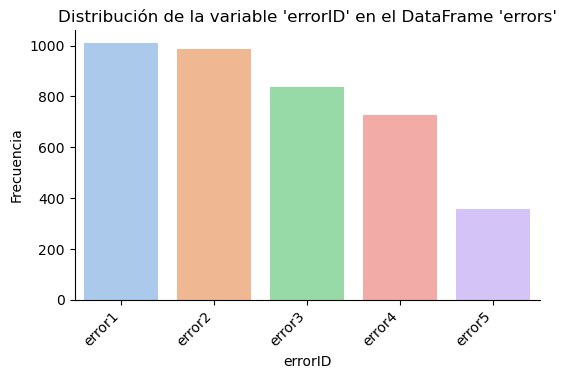

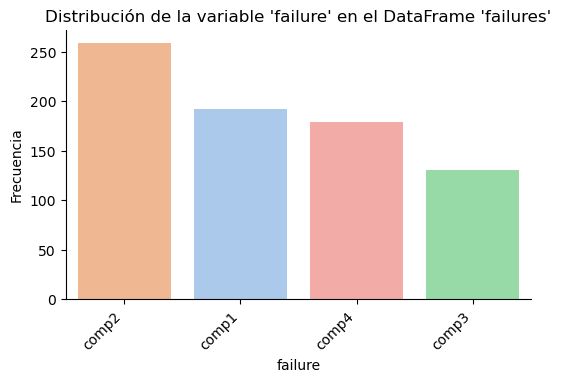

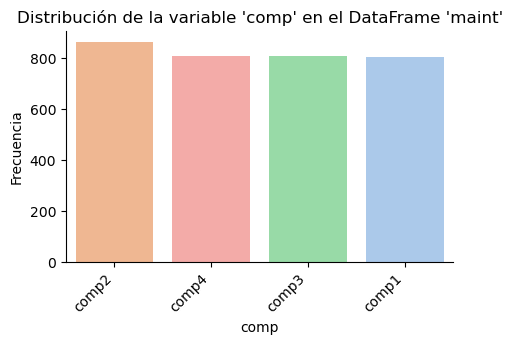

In [12]:
# Visualizar la distribución de las variables categóricas errorID en el
# DataFrame 'errors'
plt.figure(figsize=(6, 3.5))
ax = sns.countplot(
    data=dfs["errors"],
    x="errorID",
    hue="errorID",
    order=dfs["errors"]["errorID"].value_counts().index,
    palette="pastel",
    legend=False,
)
ax.set_title("Distribución de la variable 'errorID' en el DataFrame 'errors'")
ax.set_xlabel("errorID")
ax.set_ylabel("Frecuencia")
plt.xticks(rotation=45, ha="right")
sns.despine()
plt.savefig(
    os.path.join(images_dir, "errors_errorID_distribution.png"),
    bbox_inches="tight",
)
plt.show()

# Visualizar la distribución de las variables categóricas failure en el
# DataFrame 'failures'
plt.figure(figsize=(6, 3.5))
ax = sns.countplot(
    data=dfs["failures"],
    x="failure",
    hue="failure",
    order=dfs["failures"]["failure"].value_counts().index,
    palette="pastel",
    legend=False,
)
ax.set_title("Distribución de la variable 'failure' en el DataFrame 'failures'")
ax.set_xlabel("failure")
ax.set_ylabel("Frecuencia")
plt.xticks(rotation=45, ha="right")
sns.despine()
plt.savefig(
    os.path.join(images_dir, "failures_failure_distribution.png"),
    bbox_inches="tight",
)
plt.show()

# Visualizar la distribución de las variables categóricas comp en el
# DataFrame 'maint'
plt.figure(figsize=(5, 3))
ax = sns.countplot(
    data=dfs["maint"],
    x="comp",
    hue="comp",
    order=dfs["maint"]["comp"].value_counts().index,
    palette="pastel",
    legend=False,
)
ax.set_title("Distribución de la variable 'comp' en el DataFrame 'maint'")
ax.set_xlabel("comp")
ax.set_ylabel("Frecuencia")
plt.xticks(rotation=45, ha="right")
sns.despine()
plt.savefig(
    os.path.join(images_dir, "maint_comp_distribution.png"),
    bbox_inches="tight",
)
plt.show()

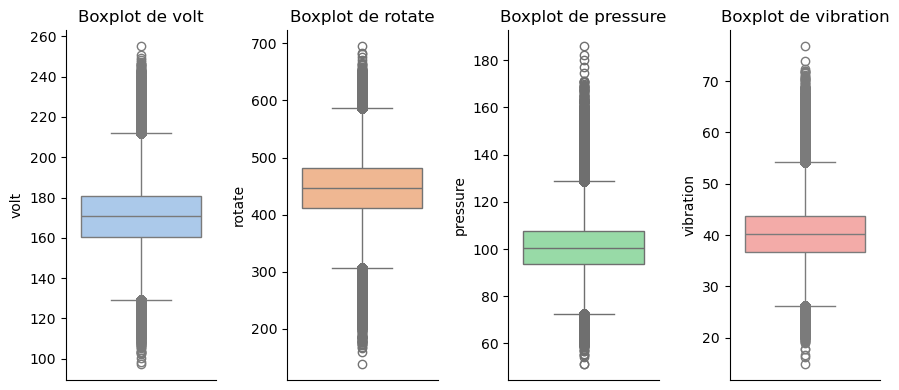

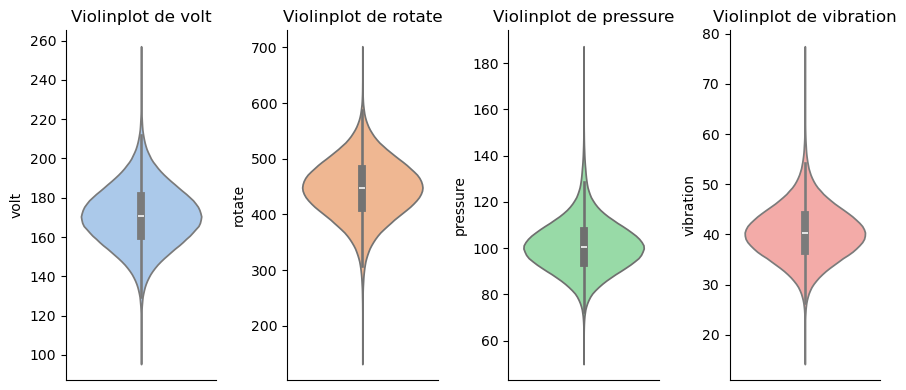

In [13]:
# Diagramas de box globales para las variables de telemetría en el DataFrame
# 'telemetry'
telemetry_vars = ["volt", "rotate", "pressure", "vibration"]
pastel_colors = sns.color_palette("pastel", n_colors=len(telemetry_vars))
plt.figure(figsize=(9, 4))
for i, (var, color) in enumerate(zip(telemetry_vars, pastel_colors), 1):
    plt.subplot(1, 4, i)
    sns.boxplot(y=dfs["telemetry"][var], color=color)
    plt.title(f"Boxplot de {var}")
    plt.ylabel(var)
    plt.xlabel("")
    plt.xticks([])
    sns.despine(ax=plt.gca(), top=True, right=True)
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_continuous_variables_boxplots.png"),
    bbox_inches="tight",
)
plt.show()

# Diagramas de violín globales para las variables de telemetría en el DataFrame
# 'telemetry' con el boxplot dentro del diagrama de violín
plt.figure(figsize=(9, 4))
for i, (var, color) in enumerate(zip(telemetry_vars, pastel_colors), 1):
    plt.subplot(1, 4, i)
    sns.violinplot(y=dfs["telemetry"][var], inner="box", color=color)
    plt.title(f"Violinplot de {var}")
    plt.ylabel(var)
    plt.xlabel("")
    plt.xticks([])
    sns.despine(ax=plt.gca(), top=True, right=True)
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_continuous_variables_violinplots.png"),
    bbox_inches="tight",
)
plt.show()

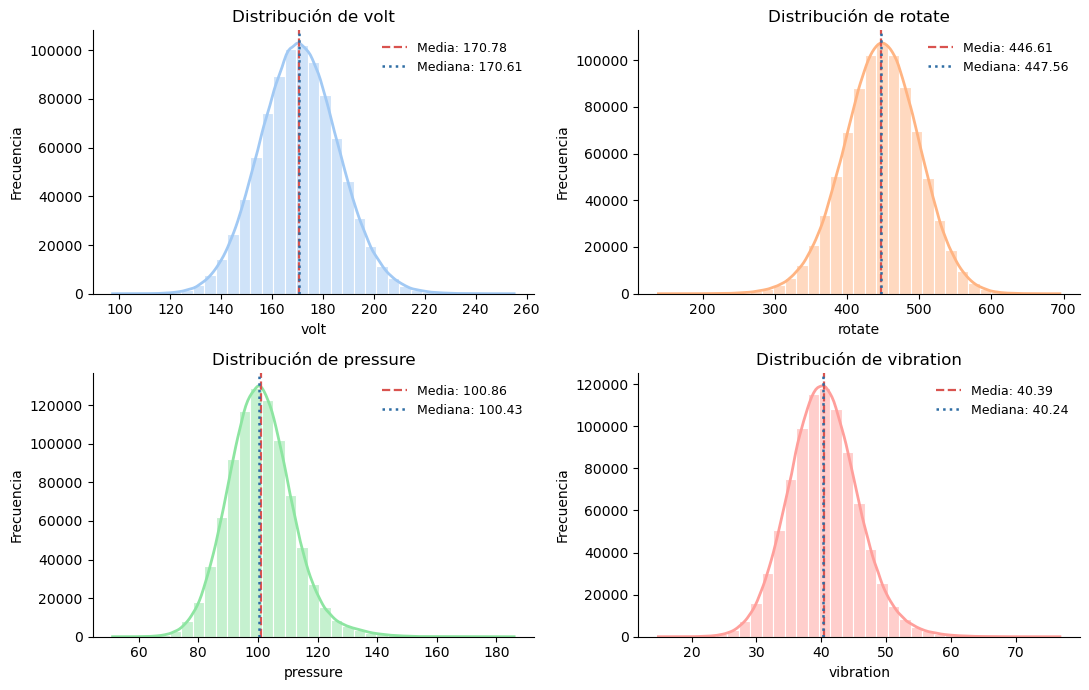

In [14]:
telemetry_vars = ["volt", "rotate", "pressure", "vibration"]
pastel_colors = sns.color_palette("pastel", n_colors=len(telemetry_vars))

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes = axes.flatten()

for ax, var, color in zip(axes, telemetry_vars, pastel_colors):
    data = dfs["telemetry"][var].dropna()
    mean_val = data.mean()
    median_val = data.median()

    sns.histplot(
        data,
        bins=35,
        kde=True,
        ax=ax,
        color=color,
        edgecolor="white",
        linewidth=0.8,
        line_kws={"linewidth": 2, "color": "#4A4A4A"},
    )

    ax.axvline(
        mean_val,
        color="#D9534F",
        linestyle="--",
        linewidth=1.6,
        label=f"Media: {mean_val:.2f}",
    )
    ax.axvline(
        median_val,
        color="#2E6DA4",
        linestyle=":",
        linewidth=1.8,
        label=f"Mediana: {median_val:.2f}",
    )

    ax.set_title(f"Distribución de {var}")
    ax.set_xlabel(var)
    ax.set_ylabel("Frecuencia")
    ax.legend(frameon=False, fontsize=9)
    sns.despine(ax=ax)

plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_continuous_variables_distributions.png"),
    bbox_inches="tight",
)
plt.show()

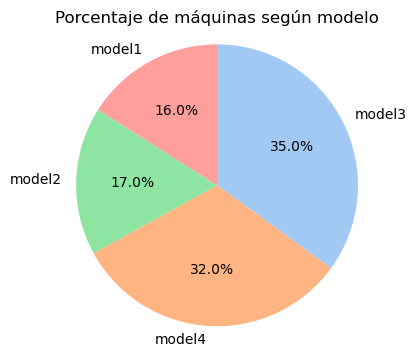

In [15]:
# Diagrama circular del número de máquinas por modelo en el DataFrame
# 'machines', ordenado por el número de máquinas de cada modelo
machine_counts = dfs["machines"]["model"].value_counts()
plt.figure(figsize=(4, 4))
plt.pie(
    machine_counts,
    labels=machine_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    colors=sns.color_palette("pastel"),
)
plt.title("Porcentaje de máquinas según modelo")
plt.axis("equal")  # Para que el gráfico sea un círculo perfecto
plt.savefig(
    os.path.join(images_dir, "machines_model_pie.png"),
    bbox_inches="tight",
)
plt.show()

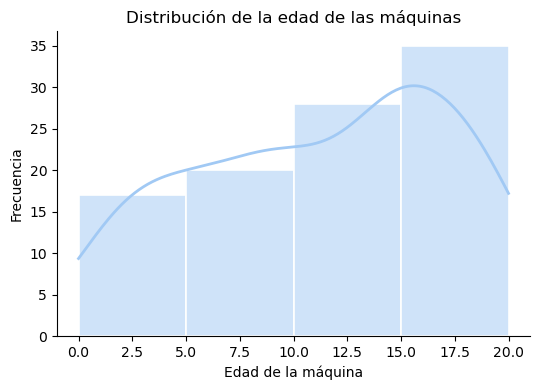

In [16]:
# Distribución de la edad de las máquinas en el DataFrame 'machines' en un
# histograma con densidad de kernel (KDE)
pastel = sns.color_palette("pastel")
plt.figure(figsize=(5.5, 4))
ax = sns.histplot(
    data=dfs["machines"],
    x="age",
    bins=4,
    kde=True,
    color=pastel[0],
    edgecolor="white",
    linewidth=1.2,
    line_kws={"color": pastel[3], "linewidth": 2},
)
ax.set_title("Distribución de la edad de las máquinas")
ax.set_xlabel("Edad de la máquina")
ax.set_ylabel("Frecuencia")
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "machines_age_histogram.png"),
    bbox_inches="tight",
)
plt.show()

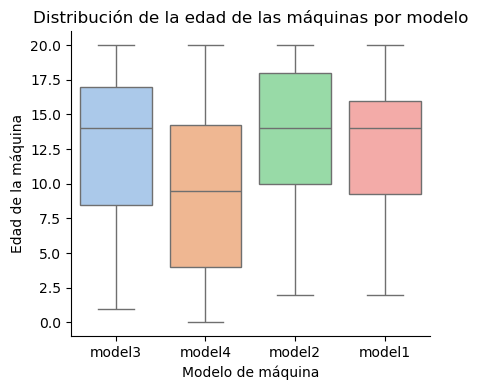

In [17]:
# Distribución de la edad de las máquinas en el DataFrame 'machines' por tipo
# de máquina con boxplot
order = dfs["machines"]["model"].value_counts().index
plt.figure(figsize=(4.5, 4))
ax = sns.boxplot(
    data=dfs["machines"],
    x="model",
    y="age",
    hue="model",
    order=order,
    palette="pastel",
    legend=False,
)
ax.set_title("Distribución de la edad de las máquinas por modelo")
ax.set_xlabel("Modelo de máquina")
ax.set_ylabel("Edad de la máquina")
sns.despine()
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "machines_age_boxplot.png"),
    bbox_inches="tight",
)
plt.show()

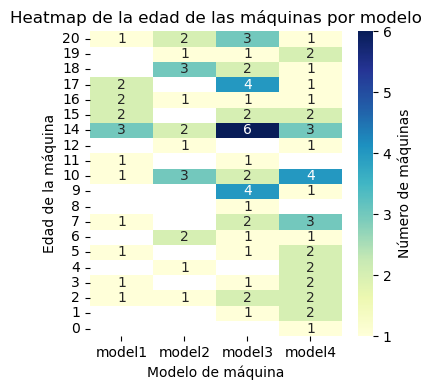

In [18]:
# Heatmap de la edad de las máquinas en el DataFrame 'machines' por tipo de
# máquina
age_machine_pivot = dfs["machines"].pivot_table(
    index="age", columns="model", values="machineID", aggfunc="count"
)

# Invertir el orden de las filas para que la edad más alta esté en la parte
# superior del heatmap
age_machine_pivot_inv = age_machine_pivot.iloc[::-1]

plt.figure(figsize=(4, 4))
sns.heatmap(
    age_machine_pivot_inv,
    annot=True,
    cmap="YlGnBu",
    cbar_kws={"label": "Número de máquinas"},
)
plt.title("Heatmap de la edad de las máquinas por modelo")
plt.xlabel("Modelo de máquina")
plt.ylabel("Edad de la máquina")
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "machines_age_heatmap.png"),
    bbox_inches="tight",
)
plt.show()

/var/folders/bw/wl8kd56j6_q7v2_t1vb4p2n00000gn/T/ipykernel_23781/2234226671.py:7: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  failures_pivot = dfs["failures"].pivot_table(
/var/folders/bw/wl8kd56j6_q7v2_t1vb4p2n00000gn/T/ipykernel_23781/2234226671.py:10: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  errors_pivot = dfs["errors"].pivot_table(


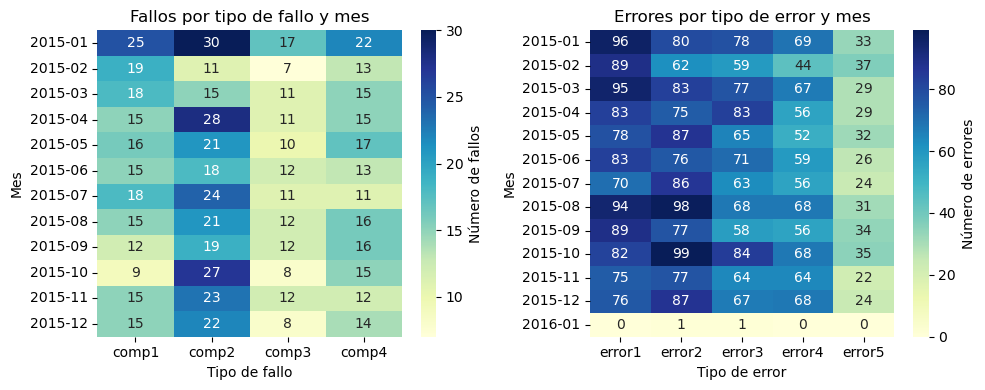

In [19]:
# Preparar los datos mensuales para 'failures' y 'errors'
dfs["failures"]["month"] = dfs["failures"]["datetime"].dt.to_period("M")
dfs["errors"]["month"] = dfs["errors"]["datetime"].dt.to_period("M")

# Crear tablas dinámicas (pivot tables) para 'failures' y 'errors' con el número
# de fallos y errores por mes y tipo
failures_pivot = dfs["failures"].pivot_table(
    index="month", columns="failure", values="machineID", aggfunc="count"
)
errors_pivot = dfs["errors"].pivot_table(
    index="month", columns="errorID", values="machineID", aggfunc="count"
)

# Crea la figura y los ejes para los heatmaps
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Heatmap de failures (izquierda)
sns.heatmap(
    failures_pivot,
    ax=axes[0],
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    cbar_kws={"label": "Número de fallos"},
)
axes[0].set_title("Fallos por tipo de fallo y mes")
axes[0].set_xlabel("Tipo de fallo")
axes[0].set_ylabel("Mes")

# Heatmap de errores (derecha)
sns.heatmap(
    errors_pivot,
    ax=axes[1],
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    cbar_kws={"label": "Número de errores"},
)
axes[1].set_title("Errores por tipo de error y mes")
axes[1].set_xlabel("Tipo de error")
axes[1].set_ylabel("Mes")

plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "failures_errors_heatmaps.png"),
    bbox_inches="tight",
)
plt.show()

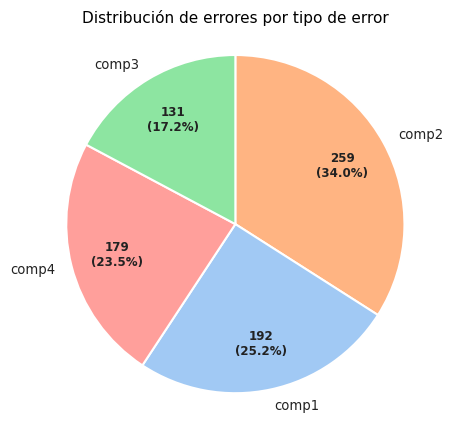

In [20]:
# Diagrama circular del número de errores por tipo de error en el DataFrame
# 'failures', ordenado por el número de errores de cada tipo
pastel = sns.color_palette("pastel")
color_map = {
    "comp2": pastel[1],
    "comp1": pastel[0],
    "comp4": pastel[3],
    "comp3": pastel[2],
}
failure_counts = dfs["failures"]["failure"].value_counts()
total = failure_counts.sum()
colors = [
    color_map.get(cat, pastel[i % len(pastel)])
    for i, cat in enumerate(failure_counts.index)
]


def fmt_valor_y_pct(pct):
    """
    Función para formatear el valor y el porcentaje en el gráfico circular.
    Parameters:
        pct (float): Porcentaje del segmento del gráfico circular.
    """
    valor = int(round(pct * total / 100.0))
    return f"{valor}\n({pct:.1f}%)"


plt.figure(figsize=(4.8, 4.8))
wedges, texts, autotexts = plt.pie(
    failure_counts,
    labels=failure_counts.index,
    autopct=fmt_valor_y_pct,
    pctdistance=0.72,
    startangle=90,
    counterclock=False,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
    textprops={"fontsize": 9.5, "color": "#222222"},
)

for autotext in autotexts:
    autotext.set_fontsize(8.5)
    autotext.set_fontweight("bold")
    autotext.set_color("#222222")

plt.title("Distribución de errores por tipo de error", fontsize=11, pad=12)
plt.axis("equal")

plt.savefig(
    os.path.join(images_dir, "failures_failure_pie.png"),
    bbox_inches="tight",
)
plt.show()

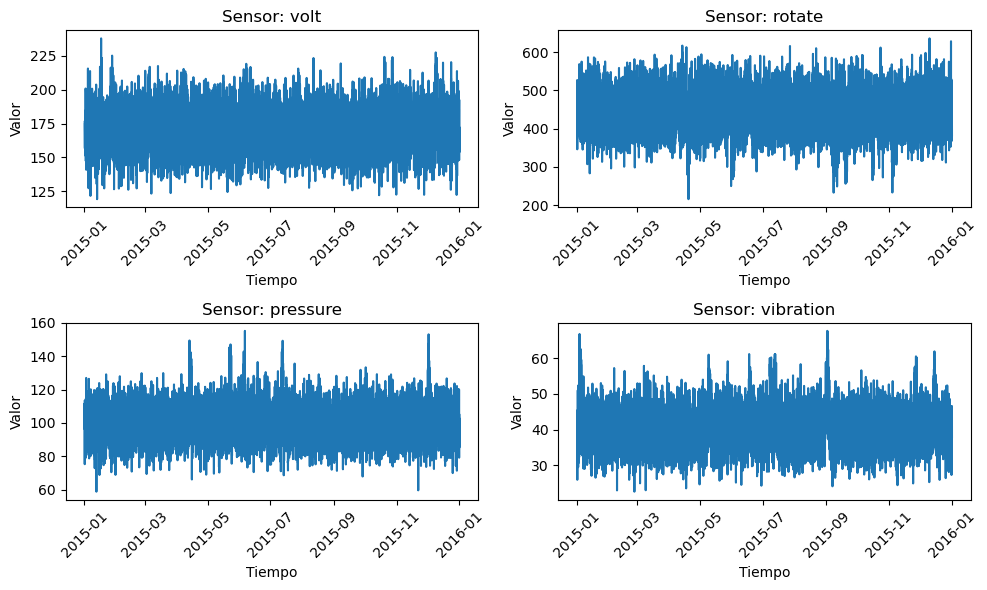

In [21]:
# Filtrar los datos de telemetría para una máquina específica (por ejemplo,
# machineID = 1) para visualizar las variables de telemetría a lo largo del
# tiempo
machine_id = 1
machine_telemetry = dfs["telemetry"][dfs["telemetry"]["machineID"] == machine_id]
plt.figure(figsize=(10, 6))
for i, sensor in enumerate(telemetry_vars, 1):
    plt.subplot(2, 2, i)
    plt.plot(machine_telemetry["datetime"], machine_telemetry[sensor])
    plt.title(f"Sensor: {sensor}")
    plt.xlabel("Tiempo")
    plt.ylabel("Valor")
    plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_machine1_timeseries.png"),
    bbox_inches="tight",
)
plt.show()

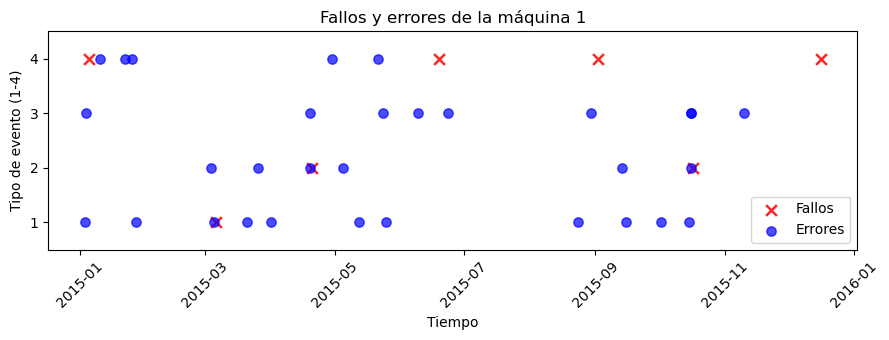


Observaciones de fallos de la máquina 1:
             datetime failure
0 2015-01-05 06:00:00   comp4
1 2015-03-06 06:00:00   comp1
2 2015-04-20 06:00:00   comp2
3 2015-06-19 06:00:00   comp4
4 2015-09-02 06:00:00   comp4
5 2015-10-17 06:00:00   comp2
6 2015-12-16 06:00:00   comp4

Observaciones de errores de la máquina 1:
              datetime errorID
0  2015-01-03 07:00:00  error1
1  2015-01-03 20:00:00  error3
2  2015-01-04 06:00:00  error5
3  2015-01-10 15:00:00  error4
4  2015-01-22 10:00:00  error4
5  2015-01-25 15:00:00  error4
6  2015-01-27 04:00:00  error1
7  2015-03-03 22:00:00  error2
8  2015-03-05 06:00:00  error1
9  2015-03-20 18:00:00  error1
10 2015-03-26 01:00:00  error2
11 2015-03-31 23:00:00  error1
12 2015-04-19 06:00:00  error2
13 2015-04-19 06:00:00  error3
14 2015-04-29 19:00:00  error4
15 2015-05-04 23:00:00  error2
16 2015-05-12 09:00:00  error1
17 2015-05-21 07:00:00  error4
18 2015-05-24 02:00:00  error3
19 2015-05-25 05:00:00  error1
20 2015-06-09 06:00:00  

In [22]:
# Filtrar los fallos y errores de la máquina seleccionada
machine_failures = dfs["failures"][dfs["failures"]["machineID"] == machine_id]
machine_errors = dfs["errors"][dfs["errors"]["machineID"] == machine_id]

# Valores enteros permitidos en el eje Y (1, 2, 3 o 4)
y_ticks = [1, 2, 3, 4]

plt.figure(figsize=(9, 3.5))

# Dibujar los fallos como cruces ('x')
plt.scatter(
    machine_failures["datetime"],
    machine_failures["failure"].cat.codes + 1,
    color="red",
    marker="x",
    s=60,
    linewidths=1.8,
    alpha=0.85,
    label="Fallos",
)

# Dibujar los errores como círculos ('o')
plt.scatter(
    machine_errors["datetime"],
    machine_errors["errorID"].cat.codes + 1,
    color="blue",
    marker="o",
    s=45,
    alpha=0.7,
    label="Errores",
)

plt.title(f"Fallos y errores de la máquina {machine_id}")
plt.xlabel("Tiempo")
plt.ylabel("Tipo de evento (1-4)")
plt.yticks(y_ticks)
plt.ylim(0.5, 4.5)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "failures_errors_machine1.png"),
    bbox_inches="tight",
)
plt.show()

# Imprimir por pantalla las observaciones de fallos y errores de la máquina
# seleccionada
print(f"\nObservaciones de fallos de la máquina {machine_id}:")
print(machine_failures[["datetime", "failure"]])
print(f"\nObservaciones de errores de la máquina {machine_id}:")
print(machine_errors[["datetime", "errorID"]])

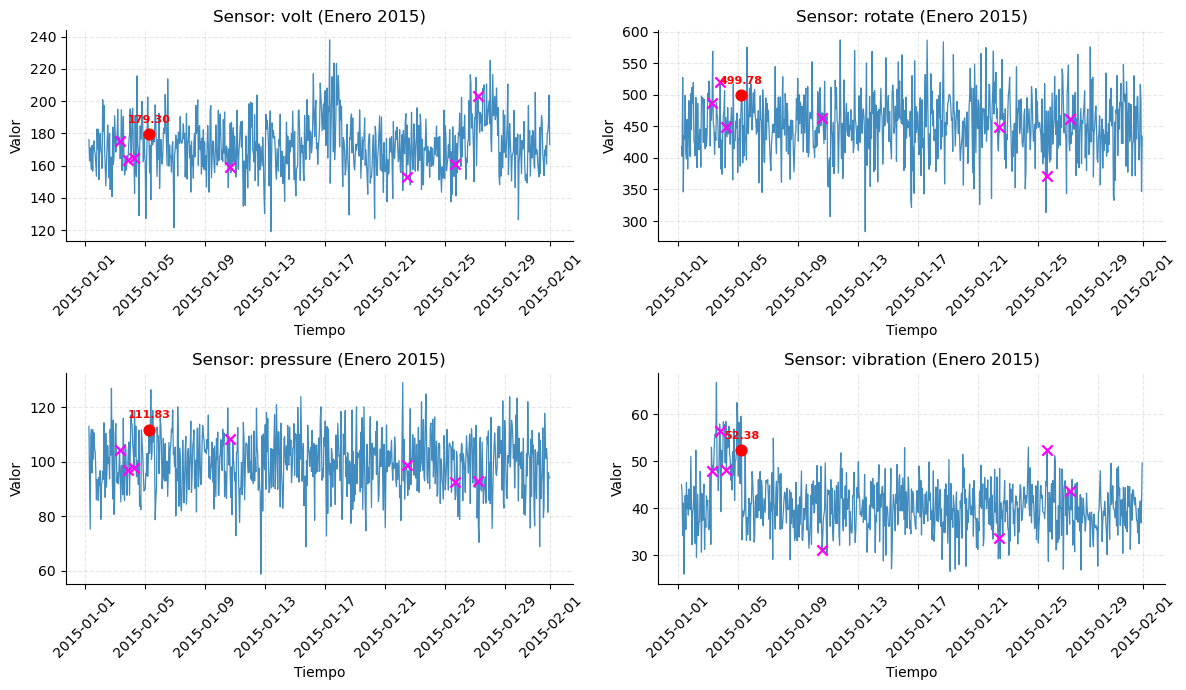

In [23]:
# Filtrar la telemetría, fallos y errores de enero de 2015 para la máquina
# seleccionada
start_date = "2015-01-01"
end_date = "2015-02-01"

machine_telemetry_filtered = machine_telemetry[
    (machine_telemetry["datetime"] >= start_date)
    & (machine_telemetry["datetime"] < end_date)
].sort_values("datetime")

# Filtrar los fallos de la máquina en enero de 2015
failures_filtered = dfs["failures"][
    (dfs["failures"]["machineID"] == machine_id)
    & (dfs["failures"]["datetime"] >= start_date)
    & (dfs["failures"]["datetime"] < end_date)
].sort_values("datetime")

# Filtrar los errores de la máquina en enero de 2015
errors_filtered = dfs["errors"][
    (dfs["errors"]["machineID"] == machine_id)
    & (dfs["errors"]["datetime"] >= start_date)
    & (dfs["errors"]["datetime"] < end_date)
].sort_values("datetime")

# Asociar cada fallo al dato de telemetría más cercano en el tiempo
failure_points = pd.merge_asof(
    failures_filtered[["datetime", "failure"]],
    machine_telemetry_filtered[["datetime"] + telemetry_vars],
    on="datetime",
    direction="nearest",
)

# Asociar cada error al dato de telemetría más cercano en el tiempo
error_points = pd.merge_asof(
    errors_filtered[["datetime", "errorID"]],
    machine_telemetry_filtered[["datetime"] + telemetry_vars],
    on="datetime",
    direction="nearest",
)

plt.figure(figsize=(12, 7))

for i, sensor in enumerate(telemetry_vars, 1):
    ax = plt.subplot(2, 2, i)

    # Línea principal de telemetría estilizada con trazo fino y limpio
    ax.plot(
        machine_telemetry_filtered["datetime"],
        machine_telemetry_filtered[sensor],
        color="#1f77b4",
        linewidth=0.9,
        alpha=0.85,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=2,
    )

    # Marcar los errores con cruces de color fucsia
    if not error_points.empty:
        ax.scatter(
            error_points["datetime"],
            error_points[sensor],
            color="fuchsia",
            marker="x",
            s=55,
            linewidths=1.6,
            zorder=4,
        )

    # Marcar los fallos con un punto rojo y mostrar su valor en rojo
    if not failure_points.empty:
        ax.scatter(
            failure_points["datetime"],
            failure_points[sensor],
            color="red",
            s=60,
            zorder=5,
        )

        for _, row in failure_points.iterrows():
            data_value = row[sensor]
            ax.annotate(
                f"{data_value:.2f}",
                xy=(row["datetime"], data_value),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                color="red",
                fontweight="bold",
                fontsize=8,
                zorder=6,
            )

    ax.set_title(f"Sensor: {sensor} (Enero 2015)")
    ax.set_xlabel("Tiempo")
    ax.set_ylabel("Valor")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_machine1_january2015.png"),
    bbox_inches="tight",
)
plt.show()

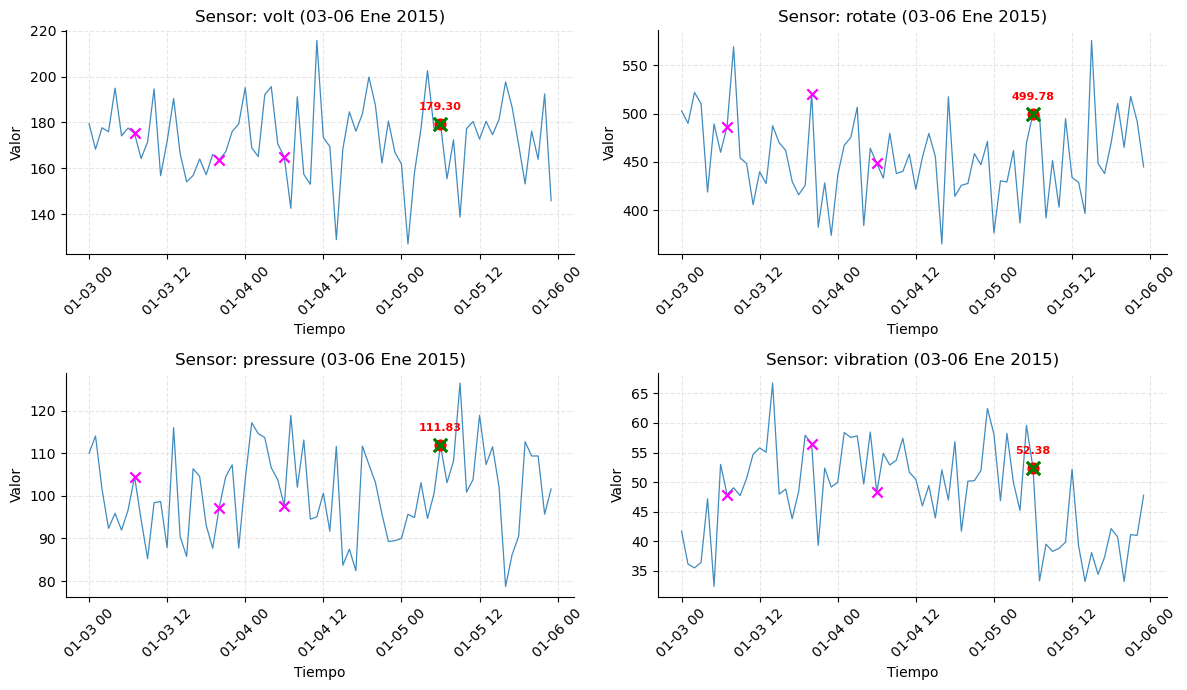

In [24]:
# Filtrar la telemetría, fallos, errores y mantenimientos del rango seleccionado
start_date = "2015-01-03"
end_date = "2015-01-06"

machine_telemetry_filtered = machine_telemetry[
    (machine_telemetry["datetime"] >= start_date)
    & (machine_telemetry["datetime"] < end_date)
].sort_values("datetime")

# Filtrar los fallos de la máquina en el rango seleccionado
failures_filtered = dfs["failures"][
    (dfs["failures"]["machineID"] == machine_id)
    & (dfs["failures"]["datetime"] >= start_date)
    & (dfs["failures"]["datetime"] < end_date)
].sort_values("datetime")

# Filtrar los errores de la máquina en el rango seleccionado
errors_filtered = dfs["errors"][
    (dfs["errors"]["machineID"] == machine_id)
    & (dfs["errors"]["datetime"] >= start_date)
    & (dfs["errors"]["datetime"] < end_date)
].sort_values("datetime")

# Filtrar las fechas de mantenimiento de la máquina en el rango seleccionado
maint_filtered = dfs["maint"][
    (dfs["maint"]["machineID"] == machine_id)
    & (dfs["maint"]["datetime"] >= start_date)
    & (dfs["maint"]["datetime"] < end_date)
].sort_values("datetime")

# Asociar cada fallo al dato de telemetría más cercano en el tiempo
failure_points = pd.merge_asof(
    failures_filtered[["datetime", "failure"]],
    machine_telemetry_filtered[["datetime"] + telemetry_vars],
    on="datetime",
    direction="nearest",
)

# Asociar cada error al dato de telemetría más cercano en el tiempo
error_points = pd.merge_asof(
    errors_filtered[["datetime", "errorID"]],
    machine_telemetry_filtered[["datetime"] + telemetry_vars],
    on="datetime",
    direction="nearest",
)

# Asociar cada mantenimiento al dato de telemetría más cercano en el tiempo
maint_points = pd.merge_asof(
    maint_filtered[["datetime", "comp"]],
    machine_telemetry_filtered[["datetime"] + telemetry_vars],
    on="datetime",
    direction="nearest",
)

plt.figure(figsize=(12, 7))

for i, sensor in enumerate(telemetry_vars, 1):
    ax = plt.subplot(2, 2, i)

    # Línea principal de telemetría estilizada con trazo fino y limpio
    ax.plot(
        machine_telemetry_filtered["datetime"],
        machine_telemetry_filtered[sensor],
        color="#1f77b4",
        linewidth=0.9,
        alpha=0.85,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=2,
    )

    # Marcar los errores con cruces de color fucsia
    if not error_points.empty:
        ax.scatter(
            error_points["datetime"],
            error_points[sensor],
            color="fuchsia",
            marker="x",
            s=55,
            linewidths=1.6,
            zorder=4,
        )

    # Marcar los fallos con un punto rojo y mostrar su valor en rojo
    if not failure_points.empty:
        ax.scatter(
            failure_points["datetime"],
            failure_points[sensor],
            color="red",
            s=60,
            zorder=5,
        )

        for _, row in failure_points.iterrows():
            data_value = row[sensor]
            ax.annotate(
                f"{data_value:.2f}",
                xy=(row["datetime"], data_value),
                xytext=(0, 10),
                textcoords="offset points",
                ha="center",
                color="red",
                fontweight="bold",
                fontsize=8,
                zorder=7,
            )

    # Marcar los mantenimientos con una cruz verde por encima del punto rojo
    if not maint_points.empty:
        ax.scatter(
            maint_points["datetime"],
            maint_points[sensor],
            color="green",
            marker="x",
            s=90,
            linewidths=2.0,
            zorder=6,
        )

    ax.set_title(f"Sensor: {sensor} (03-06 Ene 2015)")
    ax.set_xlabel("Tiempo")
    ax.set_ylabel("Valor")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_machine1_january3-6_2015.png"),
    bbox_inches="tight",
)
plt.show()

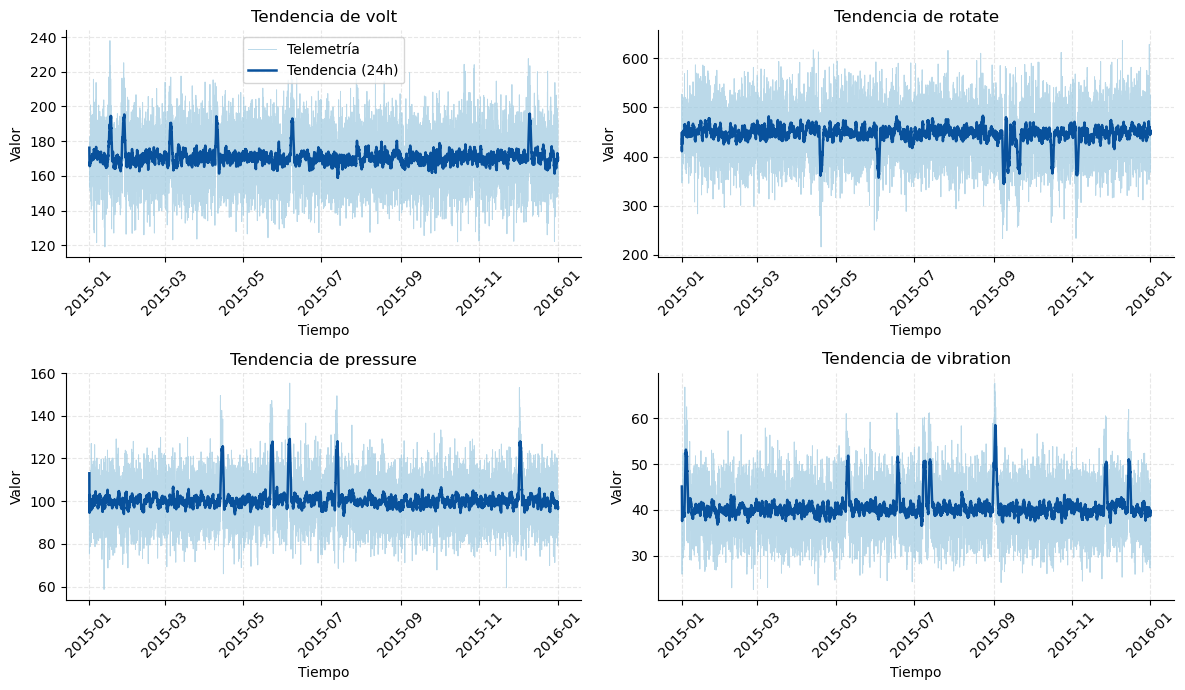

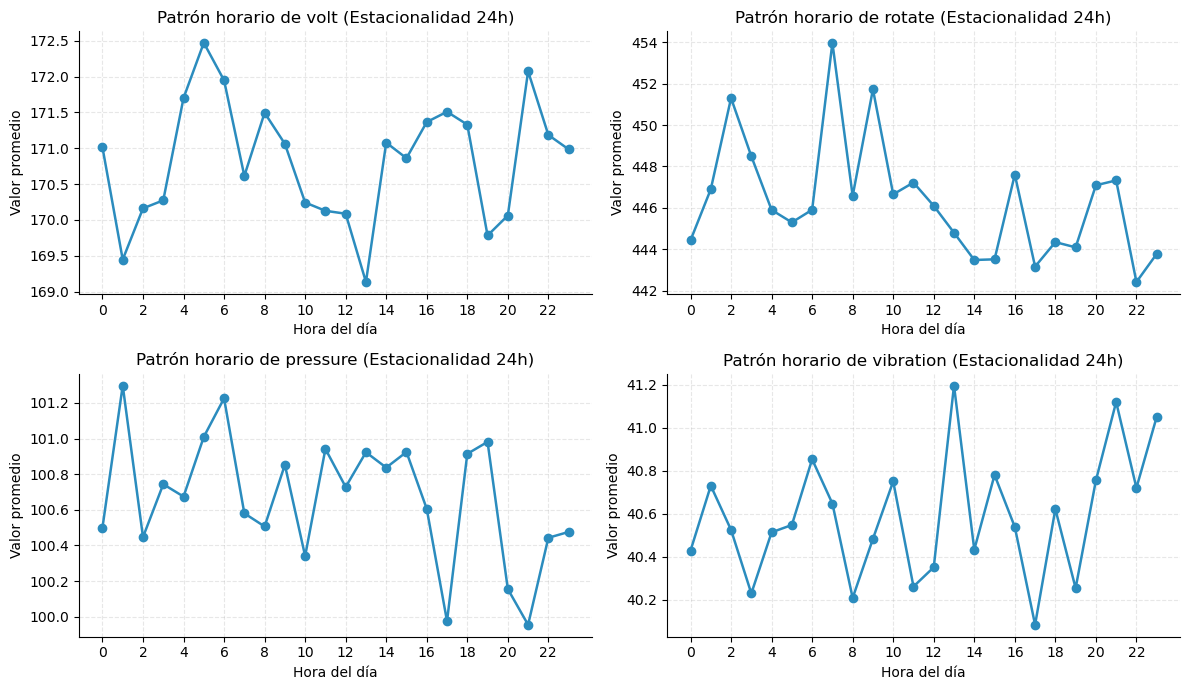

In [25]:
# Asegurar que 'datetime' esté ordenado y sea de tipo datetime
telemetry_sorted = machine_telemetry.sort_values("datetime").copy()
telemetry_sorted["datetime"] = pd.to_datetime(telemetry_sorted["datetime"])

# 1. Tendencia: media móvil de 24 horas (24 registros si los datos son horarios)
ROLLING_WINDOW = 24

plt.figure(figsize=(12, 7))
for i, sensor in enumerate(telemetry_vars, 1):
    ax = plt.subplot(2, 2, i)

    # Serie original suavizada y tendencia (media móvil de 24h)
    trend_series = (
        telemetry_sorted[sensor].rolling(window=ROLLING_WINDOW, min_periods=1).mean()
    )

    ax.plot(
        telemetry_sorted["datetime"],
        telemetry_sorted[sensor],
        color="#9ecae1",
        linewidth=0.7,
        alpha=0.7,
        label="Telemetría",
    )
    ax.plot(
        telemetry_sorted["datetime"],
        trend_series,
        color="#08519c",
        linewidth=1.8,
        label="Tendencia (24h)",
    )

    ax.set_title(f"Tendencia de {sensor}")
    ax.set_xlabel("Tiempo")
    ax.set_ylabel("Valor")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", rotation=45)
    if i == 1:
        ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "telemetry_machine1_trend_24h.png"),
    bbox_inches="tight",
)
plt.show()

# 2. Estacionalidad diaria: promedio por hora del día (0 a 23)
hourly_profile = telemetry_sorted.groupby(telemetry_sorted["datetime"].dt.hour)[
    telemetry_vars
].mean()

plt.figure(figsize=(12, 7))
for i, sensor in enumerate(telemetry_vars, 1):
    ax = plt.subplot(2, 2, i)

    ax.plot(
        hourly_profile.index,
        hourly_profile[sensor],
        marker="o",
        linewidth=1.8,
        color="#2b8cbe",
    )
    ax.set_title(f"Patrón horario de {sensor} (Estacionalidad 24h)")
    ax.set_xlabel("Hora del día")
    ax.set_ylabel("Valor promedio")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_seasonality_daily.png",
    ),
    bbox_inches="tight",
)
plt.show()

En la gráfica de voltaje, se observa que no hay una tendencia sostenida a lo largo del tiempo, la linea de Trend se mantiene relativamente estable alrededor de 170 V, con algunas fluctuaciones y picos puntuales de unos 190-200 V que corresponden a anomalías o eventos concretos, no a una subida o bajada progresiva del voltaje de todo el año.

- Serie original (volt): oscila continuamente entre valores alrededor de los 150 V y 200 V durante todo el año sin cambiar de nivel medio.
- Trend: plana alrededor de 170, salvo picos aislados. Esto indica que el voltaje operativo de la máquina es estacionario en su nivel medio a lo largo de todo 2015.
- Seasonal: se ve como una banda densa entre -1.5 y 1.5 porque en un año entero (365 días × 24 horas = 8.760 puntos) un ciclo diario de 24 horas se repite tantas veces que los ciclos se amontonan visualmente.
- Resid: mantiene una dispersión bastante uniforme (aproximadamente entre -50 y 50), señal de que gran parte de la variabilidad es ruido o fluctuaciones no explicadas por una tendencia global.

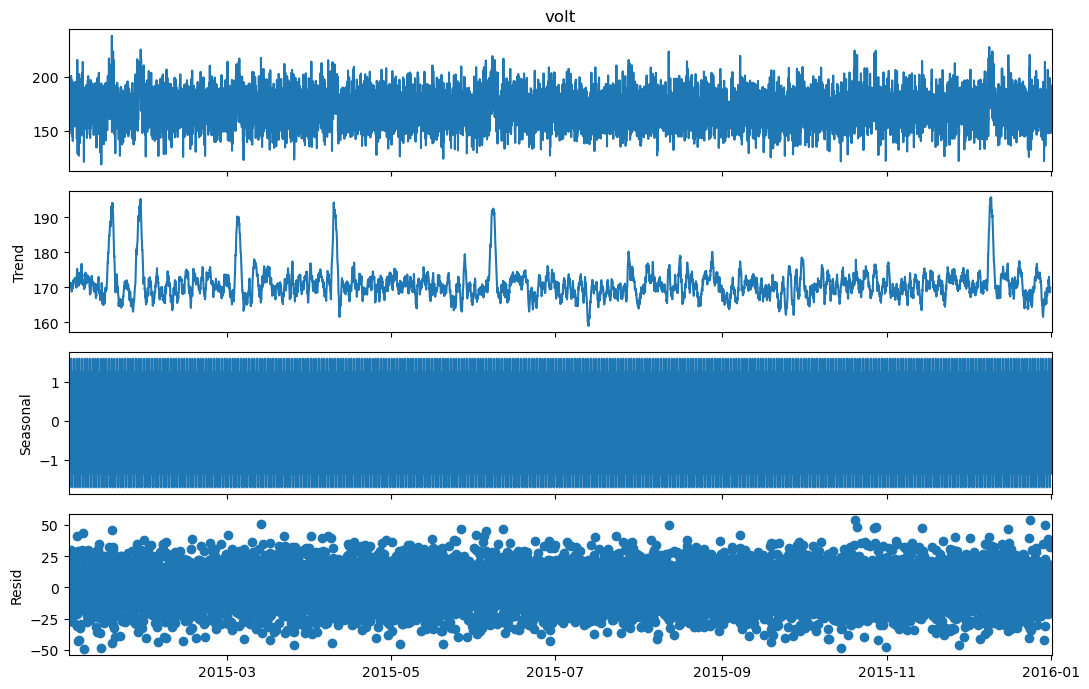

In [26]:
# Preparar serie temporal indexada por fecha con frecuencia horaria
ts_series = (
    telemetry_sorted.set_index("datetime")["volt"]
    .asfreq("h")
    .interpolate(method="time")
)

# Descomposición aditiva con estacionalidad diaria (24 horas)
decomposition = seasonal_decompose(ts_series, model="additive", period=24)

fig = decomposition.plot()
fig.set_size_inches(11, 7)
plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_seasonal_decomposition.png",
    ),
    bbox_inches="tight",
)
plt.show()

Si se cambia el tamaño de la ventana de suavizado a una semana (168 horas), se puede observar que la línea de tendencia queda más acotada (aproximadamente entre 167,5 y 177,5 V), pero aumentan los valores de la componente estacional que representan el ajuste que se suma o se resta a la tendencia (que pasa de estar entre -1,5 y +1,5 a estar entre -5 y +5).

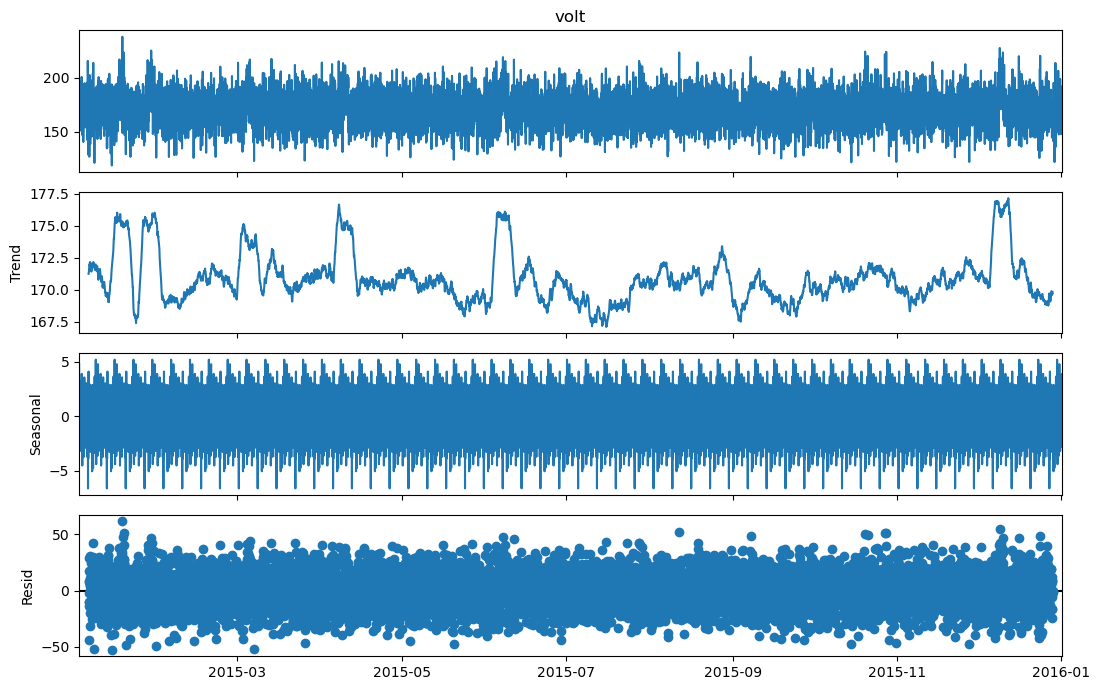

In [27]:
# Preparar serie temporal indexada por fecha con frecuencia horaria
ts_series = (
    telemetry_sorted.set_index("datetime")["volt"]
    .asfreq("h")
    .interpolate(method="time")
)

# Descomposición aditiva con estacionalidad semanal (168 horas = 24h * 7 días)
WEEKLY_PERIOD = 24 * 7
weekly_decomposition = seasonal_decompose(
    ts_series, model="additive", period=WEEKLY_PERIOD
)

fig = weekly_decomposition.plot()
fig.set_size_inches(11, 7)
plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_weekly_seasonal_decomposition.png",
    ),
    bbox_inches="tight",
)
plt.show()

La serie de rotate a lo largo de 2015 se mantiene estable en torno a un nivel base cercano a 450, sin una tendencia global sostenida al alza o a la baja, pero con caídas bruscas y localizadas (especialmente entre abril y noviembre, con descensos marcados hacia septiembre). La componente estacional aparece muy densa por la repetición del ciclo a lo largo del año y el residuo muestra una dispersión bastante uniforme alrededor de cero.

- Serie original (rotate): oscila principalmente entre valores cercanos a 350 y 550 alrededor de un nivel medio próximo a 450, con caídas puntuales que bajan hasta cerca de 200 en momentos concretos del año.
- Tendencia (Trend): permanece mayoritariamente estable alrededor de 450 sin una deriva progresiva sostenida de todo el año, aunque muestra bajadas acusadas (llegando cerca de 350, sobre todo alrededor de septiembre y en otros picos aislados) que reflejan episodios puntuales de menor rotación.
- Estacionalidad (Seasonal): se ve como una banda compacta entre aproximadamente -4 y +7 debido a que el patrón cíclico se repite muchas veces a lo largo de todo el periodo y se acumula visualmente en esta escala temporal.
- Residuo (Resid): los puntos se distribuyen de forma bastante homogénea en torno a 0 (aproximadamente entre -150 y +150, con algún punto cercano a -200), indicando fluctuaciones residuales estables sin un cambio claro en la dispersión general a lo largo del año.

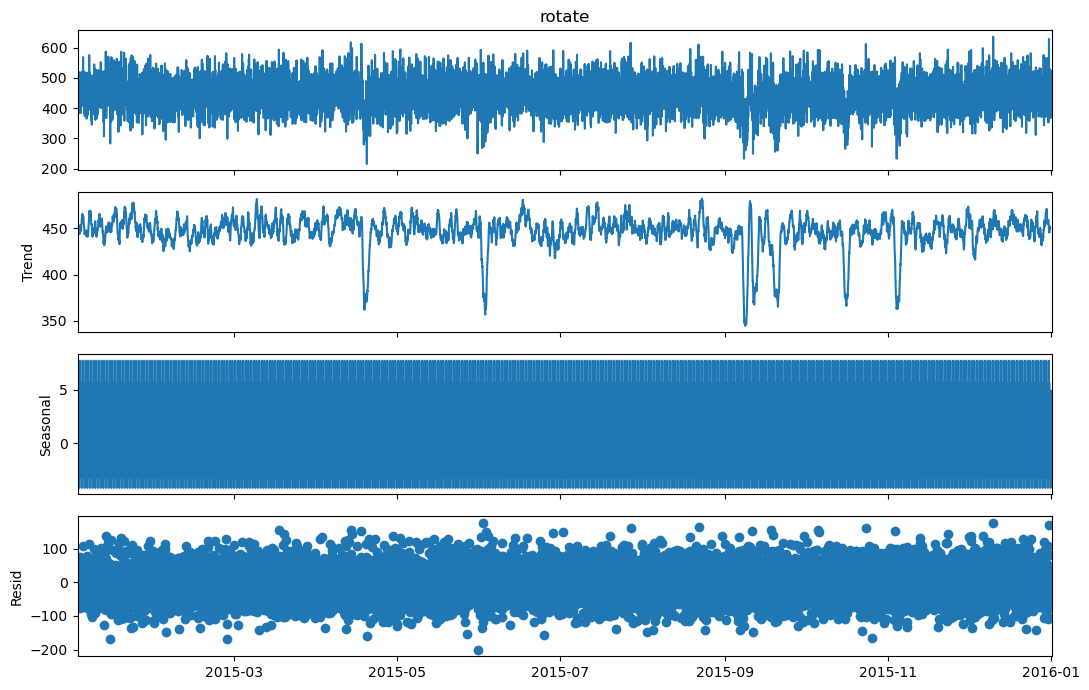

In [28]:
# Preparar serie temporal indexada por fecha con frecuencia horaria
ts_series = (
    telemetry_sorted.set_index("datetime")["rotate"]
    .asfreq("h")
    .interpolate(method="time")
)

# Descomposición aditiva con estacionalidad diaria (24 horas)
decomposition = seasonal_decompose(ts_series, model="additive", period=24)

fig = decomposition.plot()
fig.set_size_inches(11, 7)
plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_rotate_seasonal_decomposition.png",
    ),
    bbox_inches="tight",
)
plt.show()

La serie de pressure en 2015 se mantiene estable alrededor de 100 sin una tendencia global sostenida al alza o a la baja, mostrando picos puntuales que superan los 150 y una componente estacional densa por la repetición del ciclo a lo largo del año. El residuo se reparte de forma uniforme en torno a cero, por lo que los cambios más relevantes se concentran en episodios localizados más que en una deriva anual.

- Serie original (pressure): se mantiene mayoritariamente centrada en torno a 100 (con oscilaciones habituales entre 75 y 125), pero presenta picos puntuales que superan los 150 en momentos concretos del año
- Tendencia (Trend): no existe una tendencia sostenida al alza ni a la baja durante todo el periodo; el nivel base permanece estable cerca de 100, con picos aislados que alcanzan valores cercanos a 120–130 (por ejemplo, entre abril y julio y hacia diciembre)
- Estacionalidad (Seasonal): se observa una banda compacta entre aproximadamente -0.6 y +0.6 porque el ciclo periódico se repite muchas veces a lo largo de todo el año y se acumula visualmente en esa escala temporal
- Residuo (Resid): los puntos se distribuyen de forma bastante homogénea alrededor de 0 (aproximadamente entre -35 y +35), lo que sugiere que gran parte de la variación diaria o puntual corresponde a fluctuaciones o ruido residual respecto a la tendencia base

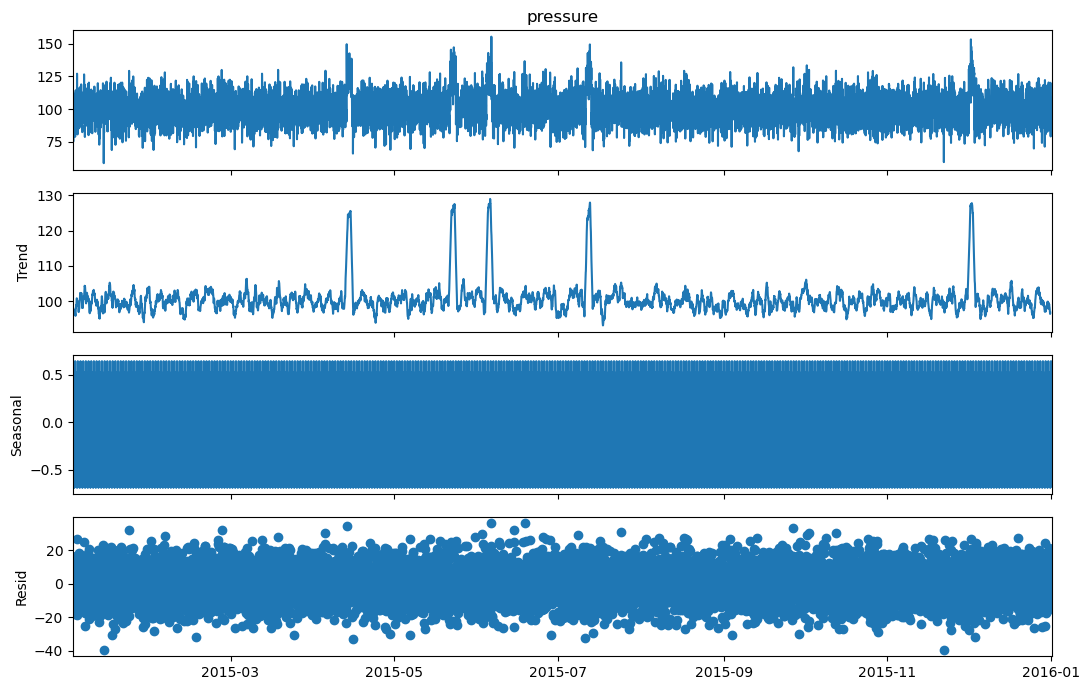

In [29]:
# Preparar serie temporal indexada por fecha con frecuencia horaria
ts_series = (
    telemetry_sorted.set_index("datetime")["pressure"]
    .asfreq("h")
    .interpolate(method="time")
)

# Descomposición aditiva con estacionalidad diaria (24 horas)
decomposition = seasonal_decompose(ts_series, model="additive", period=24)

fig = decomposition.plot()
fig.set_size_inches(11, 7)
plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_pressure_seasonal_decomposition.png",
    ),
    bbox_inches="tight",
)
plt.show()

La serie de vibration a lo largo de 2015 se mantiene estable en torno a un valor base cercano a 40, sin una tendencia sostenida a largo plazo, pero con picos aislados relevantes (especialmente cerca de septiembre de 2015). La componente estacional aparece muy compacta por la repetición del ciclo a lo largo del año y el residuo muestra una dispersión constante alrededor de cero, lo que apunta a episodios puntuales más que a una deriva anual.

- Serie original (vibration): oscila principalmente entre valores cercanos a 30 y 55 alrededor de un nivel medio en torno a 40, con elevaciones puntuales que superan los 60 en momentos concretos del año (como hacia septiembre de 2015).
- Tendencia (Trend): permanece mayoritariamente plana cerca de 40 sin un ascenso o descenso progresivo sostenido durante todo el periodo, aunque refleja picos localizados (superando los 50 y alcanzando casi 60 alrededor de septiembre) coincidiendo con episodios de mayor vibración.
- Estacionalidad (Seasonal): se observa como una franja densa entre aproximadamente -0.50 y +0.50 debido a que el patrón cíclico se repite muchas veces a lo largo del año y se apila visualmente en esta escala temporal.
- Residuo (Resid): los puntos se reparten de forma bastante homogénea en torno a 0 (aproximadamente entre -15 y +15), indicando variabilidad residual estable sin cambios estructurales evidentes en su amplitud a lo largo del año.

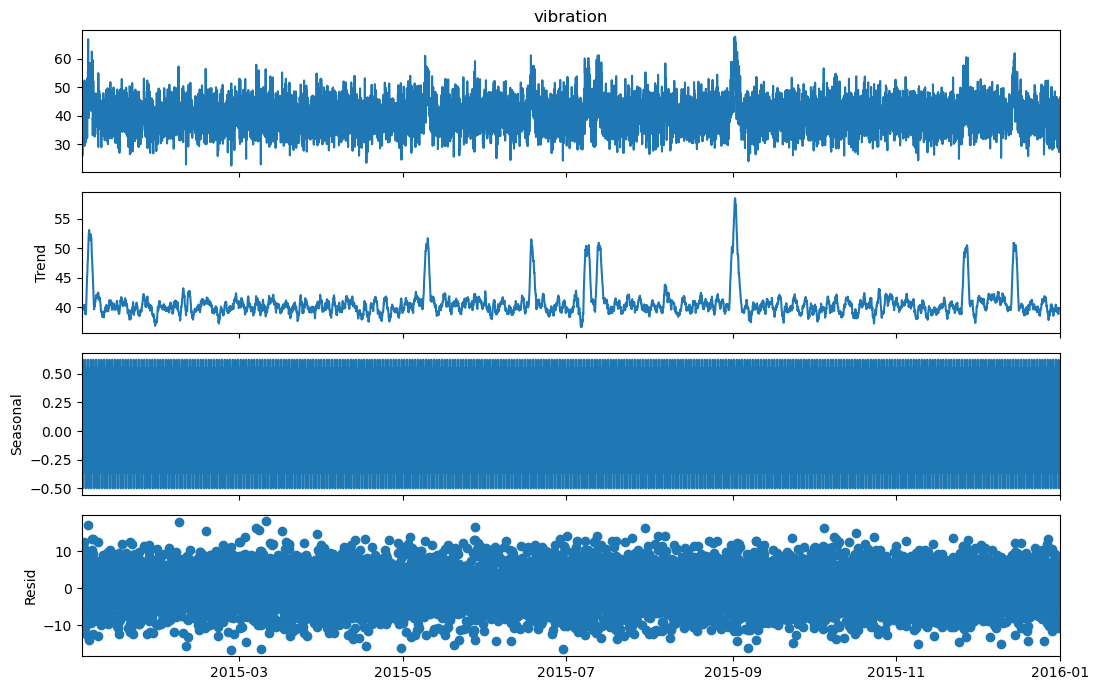

In [30]:
# Preparar serie temporal indexada por fecha con frecuencia horaria
ts_series = (
    telemetry_sorted.set_index("datetime")["vibration"]
    .asfreq("h")
    .interpolate(method="time")
)

# Descomposición aditiva con estacionalidad diaria (24 horas)
decomposition = seasonal_decompose(ts_series, model="additive", period=24)

fig = decomposition.plot()
fig.set_size_inches(11, 7)
plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_vibration_seasonal_decomposition.png",
    ),
    bbox_inches="tight",
)
plt.show()

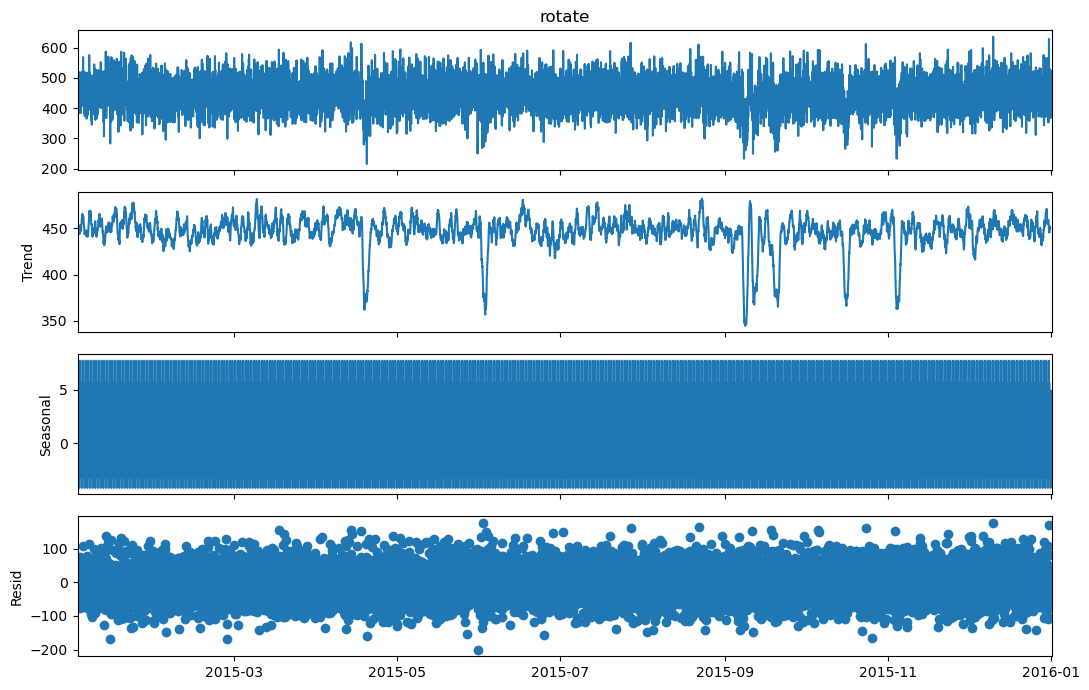

In [31]:
# Preparar serie temporal indexada por fecha con frecuencia horaria
ts_series = (
    telemetry_sorted.set_index("datetime")["rotate"]
    .asfreq("h")
    .interpolate(method="time")
)

# Descomposición aditiva con estacionalidad diaria (24 horas)
decomposition = seasonal_decompose(ts_series, model="additive", period=24)

fig = decomposition.plot()
fig.set_size_inches(11, 7)
plt.tight_layout()
plt.savefig(
    os.path.join(
        images_dir,
        "telemetry_machine1_rotate_seasonal_decomposition.png",
    ),
    bbox_inches="tight",
)
plt.show()

Comprobar si hay algún patrón en las 96 horas previas a un fallo según el tipo de fallo (componente que falla).

In [32]:
failure_types = dfs["failures"]["failure"].cat.categories
telemetry_vars = ["volt", "rotate", "pressure", "vibration"]

# Preindexamos la telemetría por máquina y ordenada por datetime para consultas rápidas
telemetry_sorted = dfs["telemetry"].sort_values(["machineID", "datetime"])
telemetry_by_machine = {}
for machine_id, grp in telemetry_sorted.groupby("machineID", sort=False):
    telemetry_by_machine[machine_id] = {
        "dt": grp["datetime"].to_numpy(),
        "values": grp[telemetry_vars].to_numpy(),
    }

# Extraemos las ventanas de 96h previas a cada ocurrencia de error
window_delta = np.timedelta64(96, "h")
one_hour_ns = np.timedelta64(1, "h")
event_frames = []

for failure in failure_types:
    error_occurrences = dfs["failures"][dfs["failures"]["failure"] == failure]

    for event_idx, row in error_occurrences.iterrows():
        machine_data = telemetry_by_machine.get(row["machineID"])
        if machine_data is None:
            continue

        failure_time = np.datetime64(row["datetime"], "ns")
        window_start = failure_time - window_delta
        dt_arr = machine_data["dt"]

        # Búsqueda binaria de los límites [window_start, failure_time)
        left = np.searchsorted(dt_arr, window_start, side="left")
        right = np.searchsorted(dt_arr, failure_time, side="left")

        if right > left:
            # Horas relativas al momento del error (p. ej., de -96 a -1)
            hours_before = ((dt_arr[left:right] - failure_time) // one_hour_ns).astype(
                np.int32
            )
            df_win = pd.DataFrame(
                machine_data["values"][left:right], columns=telemetry_vars
            )
            df_win["hours_before_error"] = hours_before
            df_win["failure_type"] = failure
            df_win["event_id"] = f"{failure}_{event_idx}"
            event_frames.append(df_win)

df_events = (
    pd.concat(event_frames, ignore_index=True) if event_frames else pd.DataFrame()
)

# Promedios por tipo de error y hora relativa (para la primera gráfica)
failure_patterns = {
    failure: grp.groupby("hours_before_error")[telemetry_vars].mean().sort_index()
    for failure, grp in df_events.groupby("failure_type", observed=False)
}

/var/folders/bw/wl8kd56j6_q7v2_t1vb4p2n00000gn/T/ipykernel_23781/3471105641.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for machine_id, grp in telemetry_sorted.groupby("machineID", sort=False):


In [33]:
# Crear un DataFrame con los promedios de cada variable de telemetría por tipo
# de error y hora relativa
avg_table = {}
avg_table["volt_comp1"] = failure_patterns.get("comp1", pd.DataFrame()).get(
    "volt", pd.Series()
)
avg_table["rotate_comp2"] = failure_patterns.get("comp2", pd.DataFrame()).get(
    "rotate", pd.Series()
)
avg_table["pressure_comp3"] = failure_patterns.get("comp3", pd.DataFrame()).get(
    "pressure", pd.Series()
)
avg_table["vibration_comp4"] = failure_patterns.get("comp4", pd.DataFrame()).get(
    "vibration", pd.Series()
)
avg_table_df = pd.DataFrame(avg_table)
# mostrar la tabla de promedios por tipo de error y hora relativa
avg_table_df

,volt_comp1,rotate_comp2,pressure_comp3,vibration_comp4
hours_before_error,,,,
-96,171.089356,442.888969,101.236993,40.492641
-95,168.466147,443.789429,102.465393,40.024944
-94,170.066090,444.711359,101.320995,40.248006
-93,170.752359,447.302250,99.899525,40.063834
-92,170.475644,442.873224,100.447425,40.005063
-91,169.987110,445.859245,100.605044,40.070439
-90,167.253903,442.370449,99.102088,40.919454
-89,171.376049,446.587549,100.648422,39.994254
-88,171.789304,451.867439,100.510128,39.810043


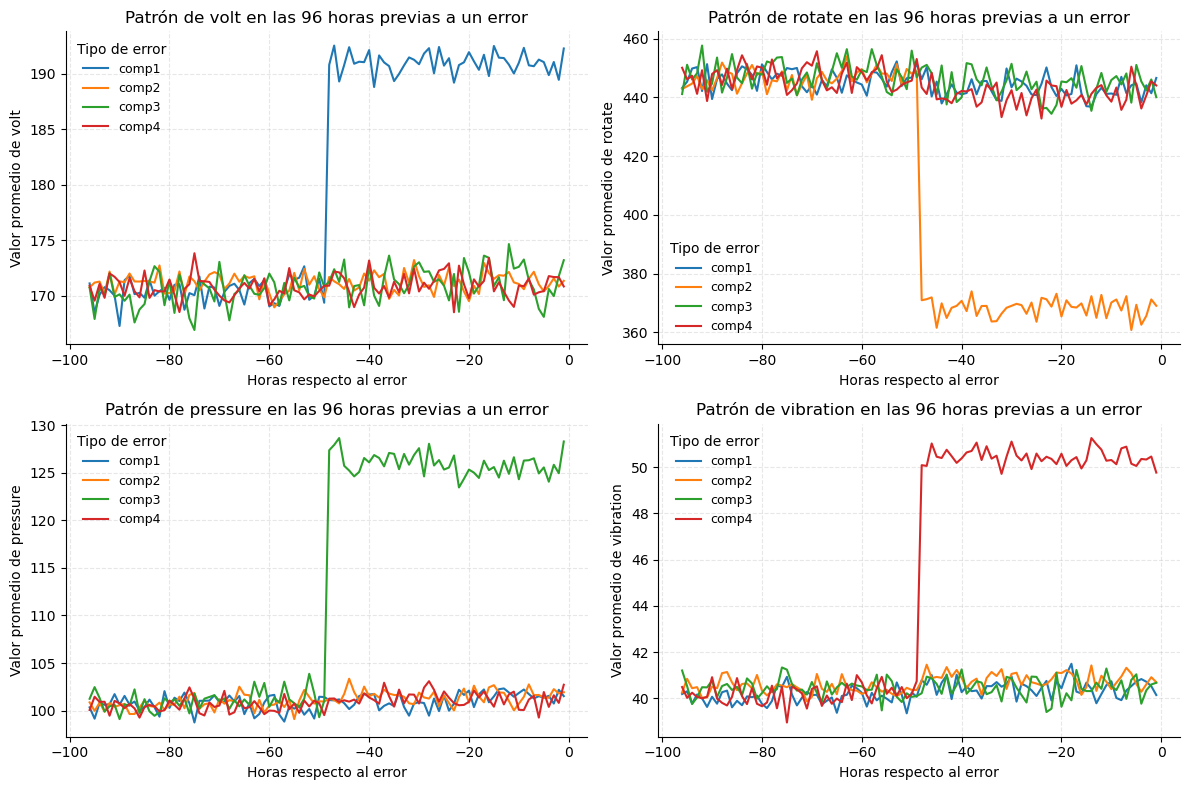

In [34]:
# Gráfico de promedio por tipo de error
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, sensor in zip(axes.flat, telemetry_vars):
    for failure, pattern in failure_patterns.items():
        ax.plot(pattern.index, pattern[sensor], label=str(failure), linewidth=1.5)

    ax.set_title(f"Patrón de {sensor} en las 96 horas previas a un error")
    ax.set_xlabel("Horas respecto al error")
    ax.set_ylabel(f"Valor promedio de {sensor}")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(title="Tipo de error", frameon=False, fontsize=9)

fig.tight_layout()
fig.savefig(
    os.path.join(images_dir, "telemetry_patterns_96h_before_errors.png"),
    bbox_inches="tight",
)
plt.show()

Mostramos las series de telemetría de las 96 horas previas a un fallo, según el tipo de fallo (componente que falla) con una ventana de suavizado de 4 horas. Se observa que los patrones de las series de telemetría varían según el tipo de fallo, lo que sugiere que ciertos tipos de fallos pueden estar asociados con cambios específicos en las variables de telemetría.

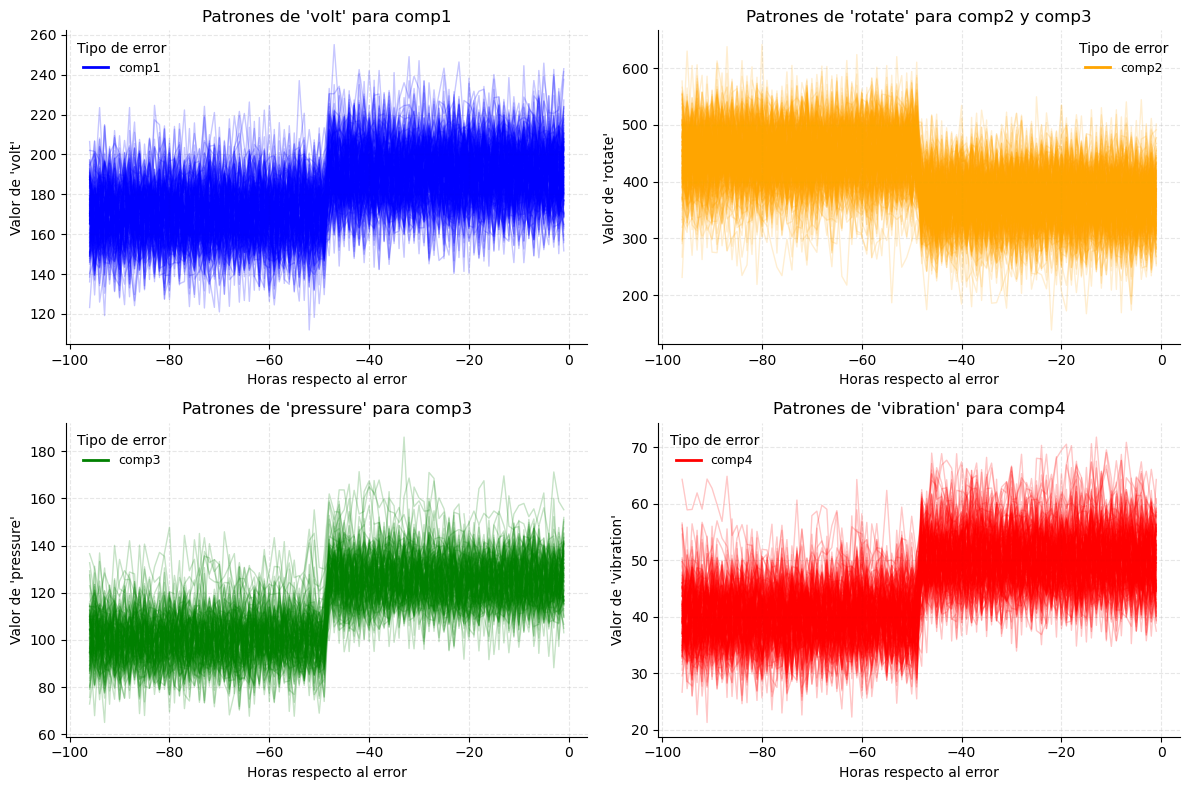

In [35]:
# Series individuales sin suavizado de ventana por ocurrencia
plot_specs = [
    ("volt", [("comp1", "blue", 0.22)], "Patrones de 'volt' para comp1"),
    (
        "rotate",
        [("comp2", "orange", 0.18)],
        "Patrones de 'rotate' para comp2 y comp3",
    ),
    (
        "pressure",
        [("comp3", "green", 0.22)],
        "Patrones de 'pressure' para comp3",
    ),
    (
        "vibration",
        [("comp4", "red", 0.22)],
        "Patrones de 'vibration' para comp4",
    ),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (sensor, failure_specs, title) in zip(axes.flat, plot_specs):
    for failure, color, line_alpha in failure_specs:
        sub = df_events[df_events["failure_type"] == failure]
        if sub.empty:
            continue

        legend_added = False
        for _, grp in sub.groupby("event_id", sort=False):
            grp_sorted = grp.sort_values("hours_before_error")

            ax.plot(
                grp_sorted["hours_before_error"],
                grp_sorted[sensor],
                color=color,
                alpha=line_alpha,
                linewidth=1.0,
                label=str(failure) if not legend_added else "_nolegend_",
            )
            legend_added = True

    ax.set_title(title)
    ax.set_xlabel("Horas respecto al error")
    ax.set_ylabel(f"Valor de '{sensor}'")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    leg = ax.legend(title="Tipo de error", frameon=False, fontsize=9)
    if leg:
        for line in leg.get_lines():
            line.set_alpha(1.0)
            line.set_linewidth(2.0)

fig.tight_layout()
fig.savefig(
    os.path.join(images_dir, "telemetry_patterns_96h_before_errors_by_variable.png"),
    bbox_inches="tight",
    dpi=200,
)
plt.show()

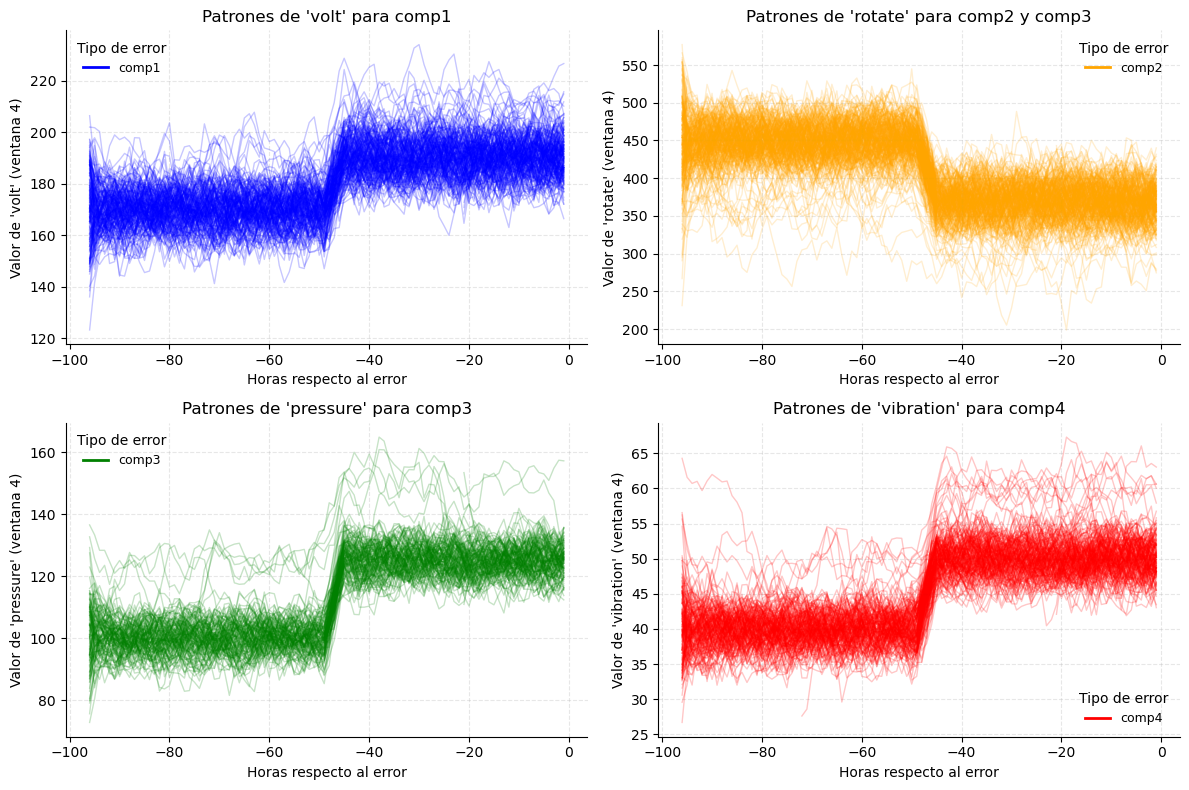

In [36]:
# Series suavizadas con ventana móvil
WINDOW_SIZE = 4

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (sensor, failure_specs, title) in zip(axes.flat, plot_specs):
    for failure, color, line_alpha in failure_specs:
        sub = df_events[df_events["failure_type"] == failure]
        if sub.empty:
            continue

        legend_added = False
        for _, grp in sub.groupby("event_id", sort=False):
            grp_sorted = grp.sort_values("hours_before_error")
            # Media móvil de 4 registros consecutivos dentro de cada ocurrencia de error
            smooth_values = (
                grp_sorted[sensor].rolling(window=WINDOW_SIZE, min_periods=1).mean()
            )

            ax.plot(
                grp_sorted["hours_before_error"],
                smooth_values,
                color=color,
                alpha=line_alpha,
                linewidth=1.0,
                label=str(failure) if not legend_added else "_nolegend_",
            )
            legend_added = True

    ax.set_title(title)
    ax.set_xlabel("Horas respecto al error")
    ax.set_ylabel(f"Valor de '{sensor}' (ventana {WINDOW_SIZE})")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    leg = ax.legend(title="Tipo de error", frameon=False, fontsize=9)
    if leg:
        for line in leg.get_lines():
            line.set_alpha(1.0)
            line.set_linewidth(2.0)

fig.tight_layout()
fig.savefig(
    os.path.join(
        images_dir, "telemetry_patterns_96h_before_errors_by_variable_smoothed.png"
    ),
    bbox_inches="tight",
    dpi=200,
)
plt.show()

In [37]:
# mostrar por pantalla un resumen de número de series de telemetría por tipo de
# fallo y variable
summary = df_events.groupby("failure_type")[telemetry_vars].count()
print("\nResumen del número de series de telemetría por tipo de fallo y variable:")
print(summary)


Resumen del número de series de telemetría por tipo de fallo y variable:
               volt  rotate  pressure  vibration
failure_type                                    
comp1         17613   17613     17613      17613
comp2         24615   24615     24615      24615
comp3         12255   12255     12255      12255
comp4         16935   16935     16935      16935


### Análisis de la calidad de los datos

Anteriormente se ha comprobado que no hay valores nulos en los DataFrames, lo que indica que no hay datos faltantes en el conjunto de datos. Además, se han convertido las variables a sus tipos de datos correspondientes para un manejo más eficiente de los datos y facilitar el análisis posterior. Para mantener una coherencia cronológica en los análisis y modelos, se ha establecido un rango de fechas común para todos los DataFrames.

En cuanto a la calidad de los datos, se ha observado que las series temporales de las variables volt, rotate, pressure y vibration se mantienen estables en torno a sus niveles base, sin tendencias sostenidas a largo plazo. Sin embargo, se han identificado picos aislados y fluctuaciones puntuales que podrían indicar eventos específicos o anomalías en el funcionamiento de la máquina. Estos valores atípicos también pueden observarse en los diagramas de caja y bigotes (boxplots) de cada variable, donde se visualizan los valores extremos que se alejan del rango intercuartílico.



In [38]:
# Comprobar que no haya valores duplicados en el dataframe de telemetría, la
# llave primaria compuesta está formada por datetime y machineID
duplicates = telemetry_sorted.duplicated(subset=["datetime", "machineID"])
if duplicates.any():
    print("Se encontraron valores duplicados en el DataFrame de telemetría:")
    print(telemetry_sorted[duplicates])
else:
    print("No se encontraron valores duplicados en el DataFrame de telemetría.")

# Comprobar si hay valores duplicados en el DataFrame de máquinas, la llave
# primaria compuesta está formada por 'machineID' y 'model'
duplicates_machines = dfs["machines"].duplicated(subset=["machineID", "model"])
if duplicates_machines.any():
    print("Se encontraron valores duplicados en el DataFrame de máquinas:")
    print(dfs["machines"][duplicates_machines])
else:
    print("No se encontraron valores duplicados en el DataFrame de máquinas.")

# Comprobar si hay valores duplicados en el DataFrame de mantenimientos, la
# llave primaria compuesta está formada por 'datetime', 'machineID' y 'comp'
duplicates_maint = dfs["maint"].duplicated(subset=["datetime", "machineID", "comp"])
if duplicates_maint.any():
    print("Se encontraron valores duplicados en el DataFrame de mantenimientos:")
    print(dfs["maint"][duplicates_maint])
else:
    print("No se encontraron valores duplicados en el DataFrame de mantenimientos.")

# Comprobar si hay valores duplicados en el DataFrame de fallos, la llave
# primaria compuesta está formada por 'datetime', 'machineID' y 'failure'
duplicates_failures = dfs["failures"].duplicated(
    subset=["datetime", "machineID", "failure"]
)
if duplicates_failures.any():
    print("Se encontraron valores duplicados en el DataFrame de fallos:")
    print(dfs["failures"][duplicates_failures])
else:
    print("No se encontraron valores duplicados en el DataFrame de fallos.")

# Comprobar si hay valores duplicados en el DataFrame de errores, la llave
# primaria compuesta está formada por 'datetime', 'machineID' y 'errorID'
duplicates_errors = dfs["errors"].duplicated(
    subset=["datetime", "machineID", "errorID"]
)
if duplicates_errors.any():
    print("Se encontraron valores duplicados en el DataFrame de errores:")
    print(dfs["errors"][duplicates_errors])
else:
    print("No se encontraron valores duplicados en el DataFrame de errores.")

No se encontraron valores duplicados en el DataFrame de telemetría.
No se encontraron valores duplicados en el DataFrame de máquinas.
No se encontraron valores duplicados en el DataFrame de mantenimientos.
No se encontraron valores duplicados en el DataFrame de fallos.
No se encontraron valores duplicados en el DataFrame de errores.


In [39]:
rows = []
window_24h = pd.Timedelta(hours=24)

for failure_type in dfs["failures"]["failure"].unique():
    failures_of_type = dfs["failures"][
        dfs["failures"]["failure"] == failure_type
    ].drop_duplicates(subset=["machineID", "datetime"])

    merged = pd.merge(
        failures_of_type,
        dfs["maint"],
        on="machineID",
        how="left",
        suffixes=("_failure", "_maint"),
    )

    time_diff = merged["datetime_maint"] - merged["datetime_failure"]
    merged_within_24h = merged[
        (time_diff >= pd.Timedelta(0)) & (time_diff <= window_24h)
    ][["machineID", "datetime_failure"]].drop_duplicates()

    total_failures_of_type = len(failures_of_type)
    num_failures_with_maint = len(merged_within_24h)
    num_failures_without_maint = total_failures_of_type - num_failures_with_maint

    rows.append(
        [
            failure_type,
            total_failures_of_type,
            num_failures_with_maint,
            num_failures_without_maint,
        ]
    )

    if num_failures_without_maint > 0:
        # Filtrar los fallos de tipo 'failure_type' que no tienen mantenimiento
        # en las 24h posteriores
        with_maint_keys = set(
            zip(merged_within_24h["machineID"], merged_within_24h["datetime_failure"])
        )
        mask_without = [
            (m, d) not in with_maint_keys
            for m, d in zip(failures_of_type["machineID"], failures_of_type["datetime"])
        ]
        failures_without_maint = failures_of_type[mask_without]

        print(
            f"\nFallos de tipo '{failure_type}' sin mantenimiento en 24h posteriores:"
        )
        print(failures_without_maint[["datetime", "machineID"]])

headers = [
    "Tipo de fallo",
    "Total de fallos",
    "Con mant. (24h post.)",
    "Sin mant. (24h post.)",
]

print(tabulate(rows, headers=headers, tablefmt="github"))


Fallos de tipo 'comp4' sin mantenimiento en 24h posteriores:
               datetime machineID
107 2015-01-02 03:00:00        17
595 2015-01-02 03:00:00        83
690 2015-01-02 03:00:00        94

Fallos de tipo 'comp1' sin mantenimiento en 24h posteriores:
               datetime machineID
94  2015-01-02 03:00:00        16
161 2015-01-02 03:00:00        22
256 2015-01-02 03:00:00        35
331 2015-01-02 03:00:00        45
373 2015-01-02 03:00:00        51
430 2015-01-02 03:00:00        59
627 2015-01-02 03:00:00        86
631 2015-01-02 03:00:00        87

Fallos de tipo 'comp2' sin mantenimiento en 24h posteriores:
               datetime machineID
422 2015-01-02 03:00:00        58
578 2015-01-02 03:00:00        80

Fallos de tipo 'comp3' sin mantenimiento en 24h posteriores:
               datetime machineID
95  2015-01-02 03:00:00        16
409 2015-01-02 03:00:00        56
739 2015-01-02 03:00:00        99
| Tipo de fallo   |   Total de fallos |   Con mant. (24h post.) |   Sin 

## Preparación de los datos

### Limpieza de los datos

### Transformación de los datos

La variable model se transforma en variables dummy para poder ser utilizada en los modelos de aprendizaje automático. Esto implica crear columnas binarias (0 o 1) para cada categoría de la variable model, lo que permite que los algoritmos de aprendizaje automático puedan interpretar correctamente esta información categórica.

In [40]:
# one-hot encoding para el modelo de las máquinas
# Creamos las variables dummy para la columna 'model' en el DataFrame de máquinas
model_dummies = pd.get_dummies(dfs["machines"]["model"], dtype=bool)
# Concatenamos las variables dummy con el DataFrame original de máquinas, excluyendo la columna 'model'
machines_encoded = pd.concat(
    [dfs["machines"].drop(columns=["model"]), model_dummies], axis=1
)

In [41]:
# Calcular las horas transcurridas desde el último mantenimiento para cada
# componente
maint_telemetry = telemetry_sorted[["datetime", "machineID"]].copy()
maint_telemetry["datetime"] = pd.to_datetime(maint_telemetry["datetime"])
maint_telemetry = maint_telemetry.sort_values("datetime")

maint_sorted = dfs["maint"].copy()
maint_sorted["datetime"] = pd.to_datetime(maint_sorted["datetime"])
maint_sorted = maint_sorted.sort_values("datetime")

for comp in ["comp1", "comp2", "comp3", "comp4"]:
    maint_comp = maint_sorted[maint_sorted["comp"] == comp][
        ["machineID", "datetime"]
    ].rename(columns={"datetime": "last_maint_dt"})

    merged = pd.merge_asof(
        maint_telemetry[["machineID", "datetime"]].reset_index(),
        maint_comp,
        left_on="datetime",
        right_on="last_maint_dt",
        by="machineID",
        direction="backward",
    ).set_index("index")

    maint_telemetry[f"last_maint_dt_{comp}"] = merged["last_maint_dt"]
    maint_telemetry[f"hours_since_maint_{comp}"] = (
        merged["datetime"] - merged["last_maint_dt"]
    ).dt.total_seconds() / 3600

maint_telemetry = maint_telemetry.reindex(telemetry_sorted.index)

print(
    "\nPrimeras filas del DataFrame de telemetría con las horas transcurridas desde el último mantenimiento por componente:"
)
# print(maint_telemetry.head())
maint_telemetry.head()


Primeras filas del DataFrame de telemetría con las horas transcurridas desde el último mantenimiento por componente:


,datetime,machineID,last_maint_dt_comp1,hours_since_maint_comp1,last_maint_dt_comp2,hours_since_maint_comp2,last_maint_dt_comp3,hours_since_maint_comp3,last_maint_dt_comp4,hours_since_maint_comp4
0,2015-01-01 06:00:00,1,2014-12-13 06:00:00,456.0,2014-06-01 06:00:00,5136.0,2014-07-31 06:00:00,3696.0,2014-07-16 06:00:00,4056.0
1,2015-01-01 07:00:00,1,2014-12-13 06:00:00,457.0,2014-06-01 06:00:00,5137.0,2014-07-31 06:00:00,3697.0,2014-07-16 06:00:00,4057.0
2,2015-01-01 08:00:00,1,2014-12-13 06:00:00,458.0,2014-06-01 06:00:00,5138.0,2014-07-31 06:00:00,3698.0,2014-07-16 06:00:00,4058.0
3,2015-01-01 09:00:00,1,2014-12-13 06:00:00,459.0,2014-06-01 06:00:00,5139.0,2014-07-31 06:00:00,3699.0,2014-07-16 06:00:00,4059.0
4,2015-01-01 10:00:00,1,2014-12-13 06:00:00,460.0,2014-06-01 06:00:00,5140.0,2014-07-31 06:00:00,3700.0,2014-07-16 06:00:00,4060.0


In [42]:
# Hay un error pen d.merge_asof porque machineID es de tipo category en ambos
# lados, pero con distintas categorías (en el lado derecho faltan máquinas como
# 6 o 77 al filtrar por componente o por los datos de failures). Cuando ambos
# lados son category, pandas exige que tengan exactamente las mismas categorías.
# Para evitar este error, creamos una copia de telemetry con las categorías
# presentes en fail_comp el identificador de máquina, y la marca temporal y
# hacemos merge_asof con esa copia.

# Preparar telemetría: convertir datetime, ordenar y guardar el dtype categórico
valid_machines = dfs["failures"]["machineID"].unique()
failures_telemetry = telemetry_sorted.loc[
    telemetry_sorted["machineID"].isin(valid_machines),
    ["datetime", "machineID"],
].copy()
failures_telemetry["datetime"] = pd.to_datetime(failures_telemetry["datetime"])
failures_telemetry = failures_telemetry.dropna(subset=["datetime"]).sort_values(
    "datetime", kind="mergesort"
)
machine_dtype = failures_telemetry["machineID"].dtype

# Preparar fallos: convertir datetime y ordenar
failures_sorted = dfs["failures"].copy()
failures_sorted["datetime"] = pd.to_datetime(failures_sorted["datetime"])
failures_sorted = failures_sorted.dropna(subset=["datetime"]).sort_values(
    "datetime", kind="mergesort"
)

# Calcular fecha del próximo fallo y horas restantes por componente
for comp in ["comp1", "comp2", "comp3", "comp4"]:
    fail_comp = (
        failures_sorted[failures_sorted["failure"] == comp][["machineID", "datetime"]]
        .rename(columns={"datetime": "next_failure_dt"})
        .sort_values("next_failure_dt", kind="mergesort")
        .copy()
    )
    # Igualar las categorías exactas de machineID con failures_telemetry
    fail_comp["machineID"] = fail_comp["machineID"].astype(machine_dtype)

    merged = pd.merge_asof(
        failures_telemetry[["machineID", "datetime"]].reset_index(),
        fail_comp,
        left_on="datetime",
        right_on="next_failure_dt",
        by="machineID",
        direction="forward",
    ).set_index("index")

    failures_telemetry[f"next_failure_dt_{comp}"] = merged["next_failure_dt"]
    failures_telemetry[f"hours_to_next_failure_{comp}"] = (
        merged["next_failure_dt"] - merged["datetime"]
    ).dt.total_seconds() / 3600

# Restaurar el orden original y visualizar
failures_telemetry = failures_telemetry.reindex(telemetry_sorted.index)

print(
    "\nPrimeros registros del DataFrame de telemetría con fecha y horas hasta el próximo fallo:"
)
# print(failures_telemetry.head())
failures_telemetry.head()


Primeros registros del DataFrame de telemetría con fecha y horas hasta el próximo fallo:


,datetime,machineID,next_failure_dt_comp1,hours_to_next_failure_comp1,next_failure_dt_comp2,hours_to_next_failure_comp2,next_failure_dt_comp3,hours_to_next_failure_comp3,next_failure_dt_comp4,hours_to_next_failure_comp4
0,2015-01-01 06:00:00,1,2015-03-06 06:00:00,1536.0,2015-04-20 06:00:00,2616.0,NaT,NaN,2015-01-05 06:00:00,96.0
1,2015-01-01 07:00:00,1,2015-03-06 06:00:00,1535.0,2015-04-20 06:00:00,2615.0,NaT,NaN,2015-01-05 06:00:00,95.0
2,2015-01-01 08:00:00,1,2015-03-06 06:00:00,1534.0,2015-04-20 06:00:00,2614.0,NaT,NaN,2015-01-05 06:00:00,94.0
3,2015-01-01 09:00:00,1,2015-03-06 06:00:00,1533.0,2015-04-20 06:00:00,2613.0,NaT,NaN,2015-01-05 06:00:00,93.0
4,2015-01-01 10:00:00,1,2015-03-06 06:00:00,1532.0,2015-04-20 06:00:00,2612.0,NaT,NaN,2015-01-05 06:00:00,92.0


In [43]:
error_codes = ["error1", "error2", "error3", "error4", "error5"]

# Calcular las horas transcurridas desde el último mantenimiento para cada
# componente
errors_telemetry = telemetry_sorted[["datetime", "machineID"]].copy()
errors_telemetry["datetime"] = pd.to_datetime(errors_telemetry["datetime"])
errors_telemetry = errors_telemetry.sort_values("datetime")

error_sorted = dfs["errors"].copy()
error_sorted["datetime"] = pd.to_datetime(error_sorted["datetime"])
error_sorted = error_sorted.sort_values("datetime")

for error_code in error_codes:
    error_comp = error_sorted[error_sorted["errorID"] == error_code][
        ["machineID", "datetime"]
    ].rename(columns={"datetime": "last_error_dt"})

    merged = pd.merge_asof(
        errors_telemetry[["machineID", "datetime"]].reset_index(),
        error_comp,
        left_on="datetime",
        right_on="last_error_dt",
        by="machineID",
        direction="backward",
    ).set_index("index")

    errors_telemetry[f"last_error_dt_{error_code}"] = merged["last_error_dt"]
    errors_telemetry[f"hours_since_last_error_{error_code}"] = (
        merged["datetime"] - merged["last_error_dt"]
    ).dt.total_seconds() / 3600

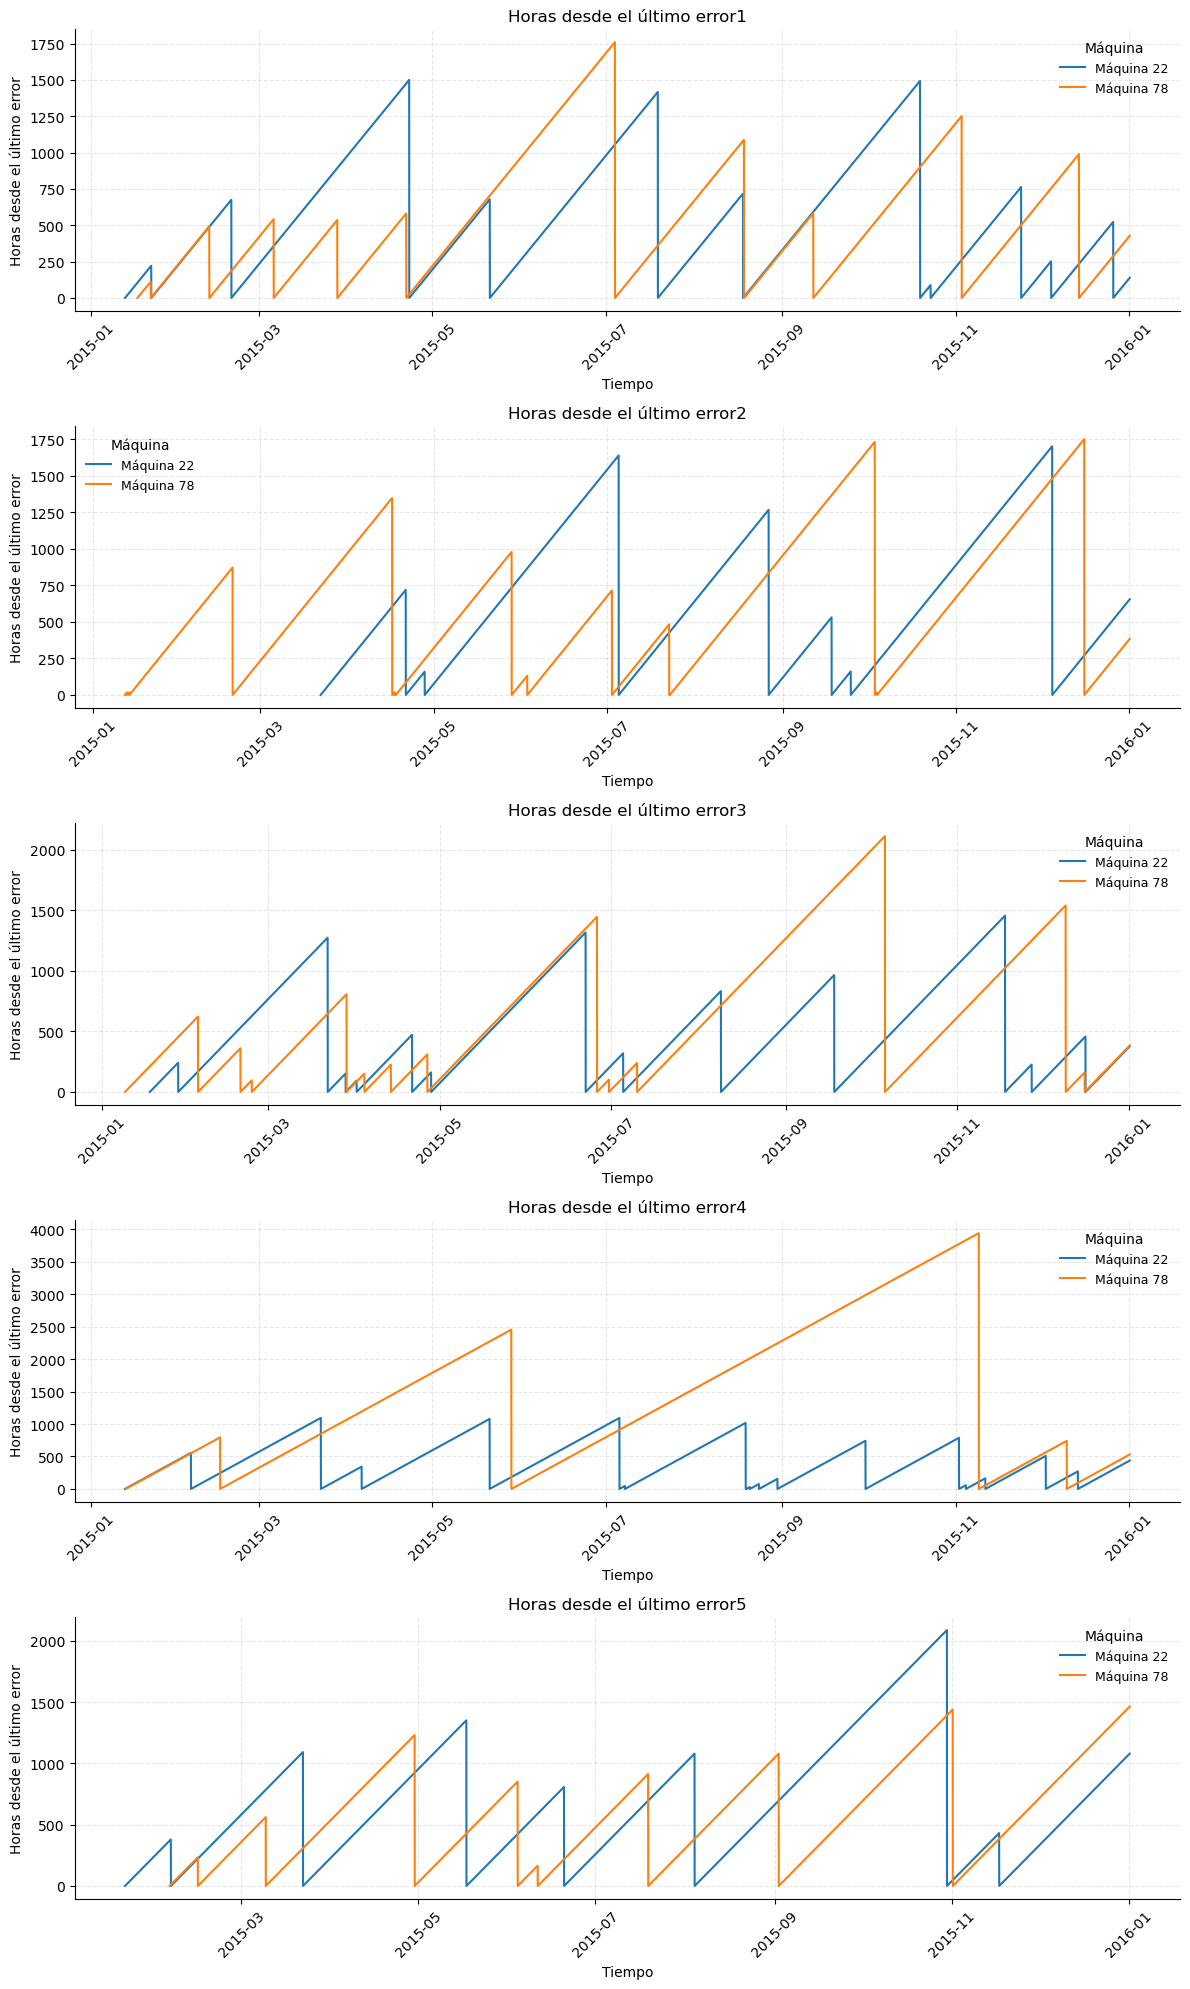

In [44]:
# Visualización de las horas desde el último error para las dos máquinas con más errores
top_machines = dfs["errors"]["machineID"].value_counts().head(2).index.tolist()

plt.figure(figsize=(12, 20))
for i, error in enumerate(error_codes, 1):
    ax = plt.subplot(5, 1, i)
    col_name = f"hours_since_last_error_{error}"

    for machine_id in top_machines:
        machine_data = errors_telemetry[
            errors_telemetry["machineID"] == machine_id
        ].sort_values("datetime")
        ax.plot(
            machine_data["datetime"],
            machine_data[col_name],
            label=f"Máquina {machine_id}",
            linewidth=1.5,
        )

    ax.set_title(f"Horas desde el último {error}")
    ax.set_xlabel("Tiempo")
    ax.set_ylabel("Horas desde el último error")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(title="Máquina", frameon=False, fontsize=9)

plt.tight_layout()
plt.savefig(
    os.path.join(images_dir, "hours_since_last_error_by_error_code.png"),
    bbox_inches="tight",
)
plt.show()

In [45]:
# print("\nPrimeras filas del DataFrame de telemetría:")
# print(telemetry_sorted.head())
# print("\nPrimeras filas del DataFrame de mantenimiento:")
# print(maint_telemetry.head())
# print("\nPrimeras filas del DataFrame de fallos:")
# print(failures_telemetry.head())

# Fusionar los dataframes telemetry_sorted con dfs["machines"]
telemetry_with_machines = pd.merge(
    telemetry_sorted,
    machines_encoded,
    on="machineID",
    how="left",
)
# Fusionar los dataframes telemetry_with_machines con maint_telemetry y
# failures_telemetry
telemetry_enriched = pd.merge(
    telemetry_with_machines,
    maint_telemetry,
    on=["datetime", "machineID"],
    how="left",
)
telemetry_enriched = pd.merge(
    telemetry_enriched,
    failures_telemetry,
    on=["datetime", "machineID"],
    how="left",
)
# Fusionar los dataframes telemetry_enriched con errors_telemetry
telemetry_enriched = pd.merge(
    telemetry_enriched,
    errors_telemetry,
    on=["datetime", "machineID"],
    how="left",
)
# Almacenar el dataframe enriquecido en un archivo CSV
telemetry_enriched.to_csv(os.path.join(data_dir, "telemetry_enriched.csv"), index=False)
# Imprimir las primeras filas del dataframe enriquecido
print("\nPrimeras filas del DataFrame de telemetría enriquecido:")
# print(telemetry_enriched.head())
telemetry_enriched.head()


Primeras filas del DataFrame de telemetría enriquecido:


,datetime,machineID,volt,rotate,pressure,vibration,age,model1,model2,model3,model4,last_maint_dt_comp1,hours_since_maint_comp1,last_maint_dt_comp2,hours_since_maint_comp2,last_maint_dt_comp3,hours_since_maint_comp3,last_maint_dt_comp4,hours_since_maint_comp4,next_failure_dt_comp1,hours_to_next_failure_comp1,next_failure_dt_comp2,hours_to_next_failure_comp2,next_failure_dt_comp3,hours_to_next_failure_comp3,next_failure_dt_comp4,hours_to_next_failure_comp4,last_error_dt_error1,hours_since_last_error_error1,last_error_dt_error2,hours_since_last_error_error2,last_error_dt_error3,hours_since_last_error_error3,last_error_dt_error4,hours_since_last_error_error4,last_error_dt_error5,hours_since_last_error_error5
0,2015-01-01 06:00:00,1,176.217853,418.504078,113.077935,45.087686,18,False,False,True,False,2014-12-13 06:00:00,456.0,2014-06-01 06:00:00,5136.0,2014-07-31 06:00:00,3696.0,2014-07-16 06:00:00,4056.0,2015-03-06 06:00:00,1536.0,2015-04-20 06:00:00,2616.0,NaT,NaN,2015-01-05 06:00:00,96.0,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN
1,2015-01-01 07:00:00,1,162.879223,402.747490,95.460525,43.413973,18,False,False,True,False,2014-12-13 06:00:00,457.0,2014-06-01 06:00:00,5137.0,2014-07-31 06:00:00,3697.0,2014-07-16 06:00:00,4057.0,2015-03-06 06:00:00,1535.0,2015-04-20 06:00:00,2615.0,NaT,NaN,2015-01-05 06:00:00,95.0,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN
2,2015-01-01 08:00:00,1,170.989902,527.349825,75.237905,34.178847,18,False,False,True,False,2014-12-13 06:00:00,458.0,2014-06-01 06:00:00,5138.0,2014-07-31 06:00:00,3698.0,2014-07-16 06:00:00,4058.0,2015-03-06 06:00:00,1534.0,2015-04-20 06:00:00,2614.0,NaT,NaN,2015-01-05 06:00:00,94.0,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN
3,2015-01-01 09:00:00,1,162.462833,346.149335,109.248561,41.122144,18,False,False,True,False,2014-12-13 06:00:00,459.0,2014-06-01 06:00:00,5139.0,2014-07-31 06:00:00,3699.0,2014-07-16 06:00:00,4059.0,2015-03-06 06:00:00,1533.0,2015-04-20 06:00:00,2613.0,NaT,NaN,2015-01-05 06:00:00,93.0,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN
4,2015-01-01 10:00:00,1,157.610021,435.376873,111.886648,25.990511,18,False,False,True,False,2014-12-13 06:00:00,460.0,2014-06-01 06:00:00,5140.0,2014-07-31 06:00:00,3700.0,2014-07-16 06:00:00,4060.0,2015-03-06 06:00:00,1532.0,2015-04-20 06:00:00,2612.0,NaT,NaN,2015-01-05 06:00:00,92.0,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN,NaT,NaN


In [46]:
# Preparar las matrices de correlación entre horas desde mantenimiento y horas hasta el próximo fallo
error_cols = [f"last_error_dt_error{i}" for i in range(1, 6)]
maint_cols = [f"hours_since_maint_comp{i}" for i in range(1, 5)]
fail_cols = [f"hours_to_next_failure_comp{i}" for i in range(1, 5)]

In [47]:
corr_pearson = (
    telemetry_enriched[maint_cols + fail_cols]
    .corr(method="pearson")
    .loc[maint_cols, fail_cols]
)
print(
    "Correlación Pearson entre horas desde el último mantenimiento y horas hasta el próximo fallo:"
)
corr_pearson.round(3)

Correlación Pearson entre horas desde el último mantenimiento y horas hasta el próximo fallo:


,hours_to_next_failure_comp1,hours_to_next_failure_comp2,hours_to_next_failure_comp3,hours_to_next_failure_comp4
hours_since_maint_comp1,-0.077,0.092,0.157,0.032
hours_since_maint_comp2,0.058,0.046,0.098,0.046
hours_since_maint_comp3,-0.003,0.109,-0.298,0.098
hours_since_maint_comp4,-0.021,0.074,0.063,-0.195


In [48]:
corr_spearman = (
    telemetry_enriched[maint_cols + fail_cols]
    .corr(method="spearman")
    .loc[maint_cols, fail_cols]
)
print(
    "\nCorrelación Spearman entre horas desde el último mantenimiento y horas hasta el próximo fallo:"
)
corr_spearman.round(3)


Correlación Spearman entre horas desde el último mantenimiento y horas hasta el próximo fallo:


,hours_to_next_failure_comp1,hours_to_next_failure_comp2,hours_to_next_failure_comp3,hours_to_next_failure_comp4
hours_since_maint_comp1,-0.262,0.090,0.103,0.062
hours_since_maint_comp2,0.054,-0.078,0.069,0.034
hours_since_maint_comp3,0.037,0.071,-0.431,0.021
hours_since_maint_comp4,-0.030,0.051,0.070,-0.447


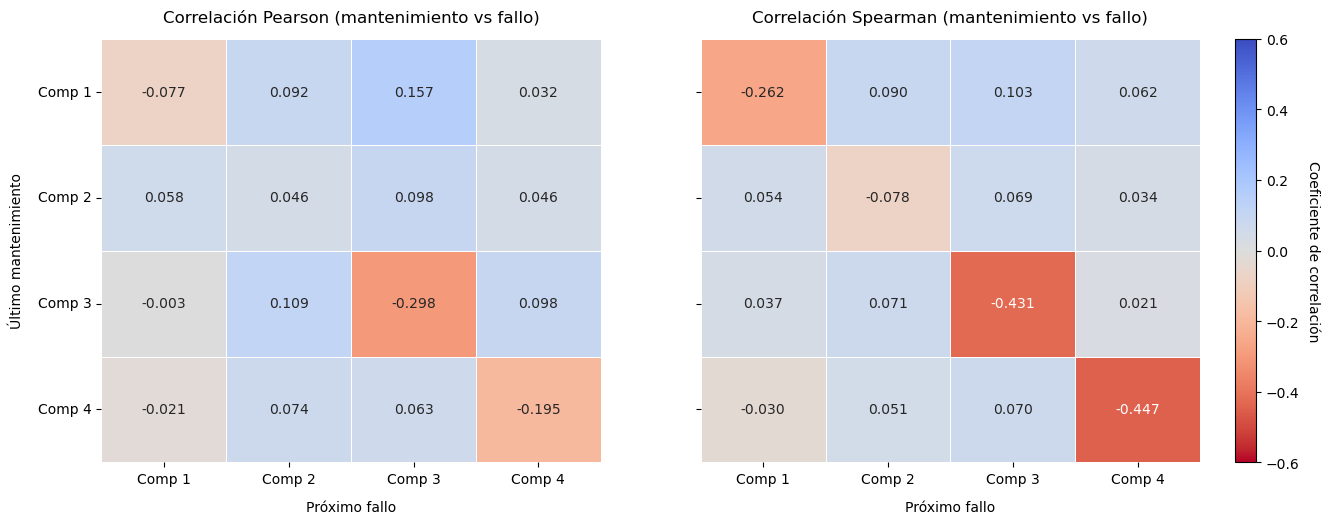

In [49]:
# Etiquetas limpias para los ejes (4 componentes en filas y columnas)
comp_labels = [f"Comp {i}" for i in range(1, 5)]
tick_positions = np.arange(len(comp_labels)) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)

# Parámetros comunes para ambos heatmaps
heatmap_kwargs = dict(
    annot=True,
    fmt=".3f",
    cmap="coolwarm_r",
    center=0,
    vmin=-0.6,
    vmax=0.6,
    linewidths=0.6,
    linecolor="white",
    annot_kws={"size": 10},
    cbar=False,  # Desactivamos la barra individual para usar una compartida
)

# Heatmap de correlación de Pearson
sns.heatmap(corr_pearson, ax=axes[0], **heatmap_kwargs)
axes[0].set_title("Correlación Pearson (mantenimiento vs fallo)", pad=12)
axes[0].set_xlabel("Próximo fallo", labelpad=10)
axes[0].set_ylabel("Último mantenimiento", labelpad=10)
axes[0].set_xticks(tick_positions)
axes[0].set_xticklabels(comp_labels, rotation=0)
axes[0].set_yticks(tick_positions)
axes[0].yaxis.set_major_formatter(FixedFormatter(comp_labels))
axes[0].tick_params(axis="y", rotation=0)
axes[0].set_yticklabels(comp_labels, rotation=0)

# Heatmap de correlación de Spearman
sns.heatmap(corr_spearman, ax=axes[1], **heatmap_kwargs)
axes[1].set_title("Correlación Spearman (mantenimiento vs fallo)", pad=12)
axes[1].set_xlabel("Próximo fallo", labelpad=10)
axes[1].set_xticks(tick_positions)
axes[1].set_xticklabels(comp_labels, rotation=0)
axes[1].set_yticks(tick_positions)
axes[1].set_yticklabels(comp_labels, rotation=0)

# Barra de color compartida a la derecha de ambos gráficos
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=plt.Normalize(vmin=-0.6, vmax=0.6))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, fraction=0.025, pad=0.03)
cbar.set_label("Coeficiente de correlación", rotation=270, labelpad=15)

# Guardamos la figura en alta resolución
plt.savefig(
    os.path.join(images_dir, "correlation_last_maintenance_next_failure.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [50]:
corr_pearson = (
    telemetry_enriched[error_cols + fail_cols]
    .corr(method="pearson")
    .loc[error_cols, fail_cols]
)
print(
    "Correlación Pearson entre horas desde el último error y horas hasta el próximo fallo:"
)
corr_pearson.round(3)

Correlación Pearson entre horas desde el último error y horas hasta el próximo fallo:


,hours_to_next_failure_comp1,hours_to_next_failure_comp2,hours_to_next_failure_comp3,hours_to_next_failure_comp4
last_error_dt_error1,-0.138,-0.149,-0.169,-0.097
last_error_dt_error2,-0.107,-0.058,-0.006,0.011
last_error_dt_error3,-0.098,-0.237,-0.106,-0.007
last_error_dt_error4,-0.216,-0.119,0.068,0.009
last_error_dt_error5,-0.038,-0.169,-0.100,-0.018


In [51]:
corr_spearman = (
    telemetry_enriched[error_cols + fail_cols]
    .corr(method="spearman")
    .loc[error_cols, fail_cols]
)
print(
    "\nCorrelación Spearman entre horas desde el último error y horas hasta el próximo fallo:"
)
corr_spearman.round(3)


Correlación Spearman entre horas desde el último error y horas hasta el próximo fallo:


,hours_to_next_failure_comp1,hours_to_next_failure_comp2,hours_to_next_failure_comp3,hours_to_next_failure_comp4
last_error_dt_error1,-0.216,-0.330,-0.160,-0.167
last_error_dt_error2,-0.244,-0.323,-0.164,-0.142
last_error_dt_error3,-0.223,-0.337,-0.153,-0.181
last_error_dt_error4,-0.279,-0.306,-0.112,-0.149
last_error_dt_error5,-0.134,-0.270,-0.110,-0.090


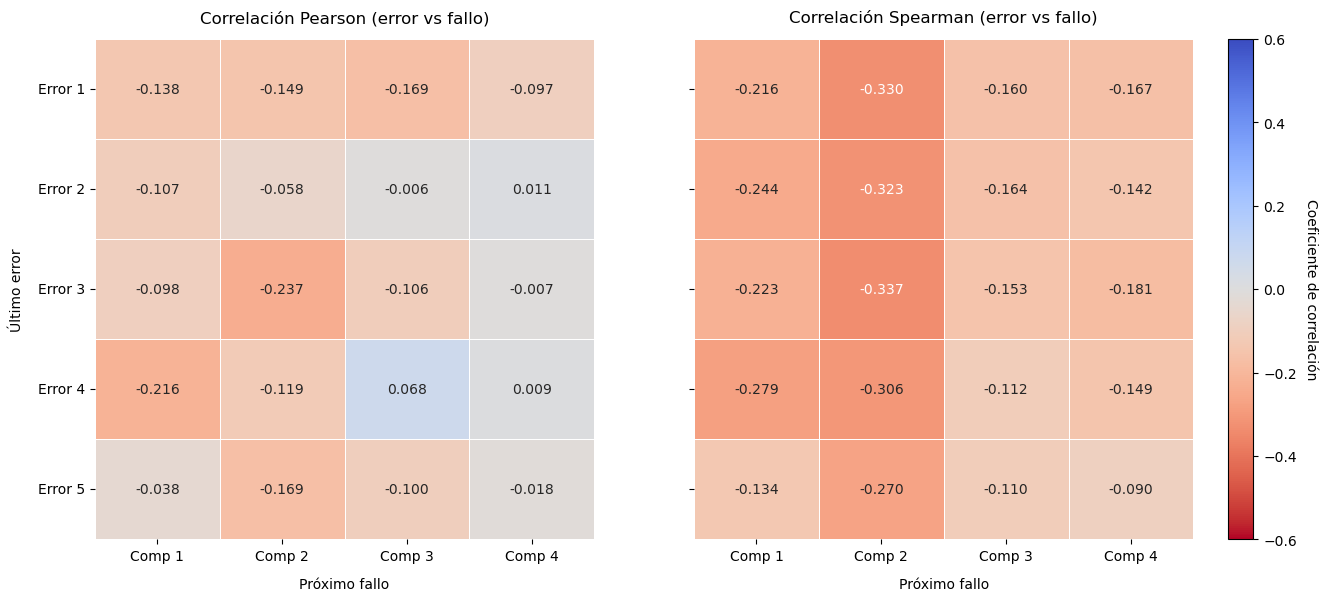

In [52]:
# Etiquetas limpias para los ejes
comp_labels = [f"Comp {i}" for i in range(1, 5)]
error_labels = [f"Error {i}" for i in range(1, 6)]

x_tick_positions = np.arange(len(comp_labels)) + 0.5
y_tick_positions = np.arange(len(error_labels)) + 0.5

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)

# Parámetros comunes para ambos heatmaps
heatmap_kwargs = dict(
    annot=True,
    fmt=".3f",
    cmap="coolwarm_r",
    center=0,
    vmin=-0.6,
    vmax=0.6,
    linewidths=0.6,
    linecolor="white",
    annot_kws={"size": 10},
    cbar=False,  # Desactivamos la barra individual para usar una compartida
)

# Heatmap de correlación de Pearson
sns.heatmap(corr_pearson, ax=axes[0], **heatmap_kwargs)
axes[0].set_title("Correlación Pearson (error vs fallo)", pad=12)
axes[0].set_xlabel("Próximo fallo", labelpad=10)
axes[0].set_ylabel("Último error", labelpad=10)
axes[0].set_xticks(x_tick_positions)
axes[0].set_xticklabels(comp_labels, rotation=0)
axes[0].set_yticks(y_tick_positions)
axes[0].set_yticklabels(error_labels, rotation=0)
axes[0].tick_params(axis="y", rotation=0)

# Heatmap de correlación de Spearman
sns.heatmap(corr_spearman, ax=axes[1], **heatmap_kwargs)
axes[1].set_title("Correlación Spearman (error vs fallo)", pad=12)
axes[1].set_xlabel("Próximo fallo", labelpad=10)
axes[1].set_xticks(x_tick_positions)
axes[1].set_xticklabels(comp_labels, rotation=0)
axes[1].set_yticks(y_tick_positions)
axes[1].set_yticklabels(error_labels, rotation=0)

# Barra de color compartida a la derecha de ambos gráficos
sm = plt.cm.ScalarMappable(cmap="coolwarm_r", norm=plt.Normalize(vmin=-0.6, vmax=0.6))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, fraction=0.025, pad=0.03)
cbar.set_label("Coeficiente de correlación", rotation=270, labelpad=15)

# Guardamos la figura en alta resolución
plt.savefig(
    os.path.join(images_dir, "correlation_last_error_next_failure.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [53]:
sensor_cols = ["volt", "rotate", "pressure", "vibration"]
corr_pearson = (
    telemetry_enriched[sensor_cols + error_cols]
    .corr(method="pearson")
    .loc[sensor_cols, error_cols]
)
print(
    "Correlación Pearson entre horas desde el último error y horas hasta el próximo fallo:"
)
corr_pearson.round(3)

Correlación Pearson entre horas desde el último error y horas hasta el próximo fallo:


,last_error_dt_error1,last_error_dt_error2,last_error_dt_error3,last_error_dt_error4,last_error_dt_error5
volt,0.002,0.000,0.001,-0.000,-0.003
rotate,0.001,-0.001,-0.004,0.002,-0.003
pressure,-0.004,0.003,-0.001,0.004,0.001
vibration,0.002,0.002,0.005,-0.001,0.011


In [54]:
corr_spearman = (
    telemetry_enriched[sensor_cols + error_cols]
    .corr(method="spearman")
    .loc[sensor_cols, error_cols]
)
print(
    "\nCorrelación Spearman entre horas desde el último error y horas hasta el próximo fallo:"
)
corr_spearman.round(3)


Correlación Spearman entre horas desde el último error y horas hasta el próximo fallo:


,last_error_dt_error1,last_error_dt_error2,last_error_dt_error3,last_error_dt_error4,last_error_dt_error5
volt,-0.000,-0.002,-0.001,-0.001,-0.003
rotate,-0.001,-0.003,-0.005,-0.001,-0.003
pressure,0.003,0.004,0.003,0.006,0.002
vibration,0.001,-0.000,-0.000,-0.001,0.007


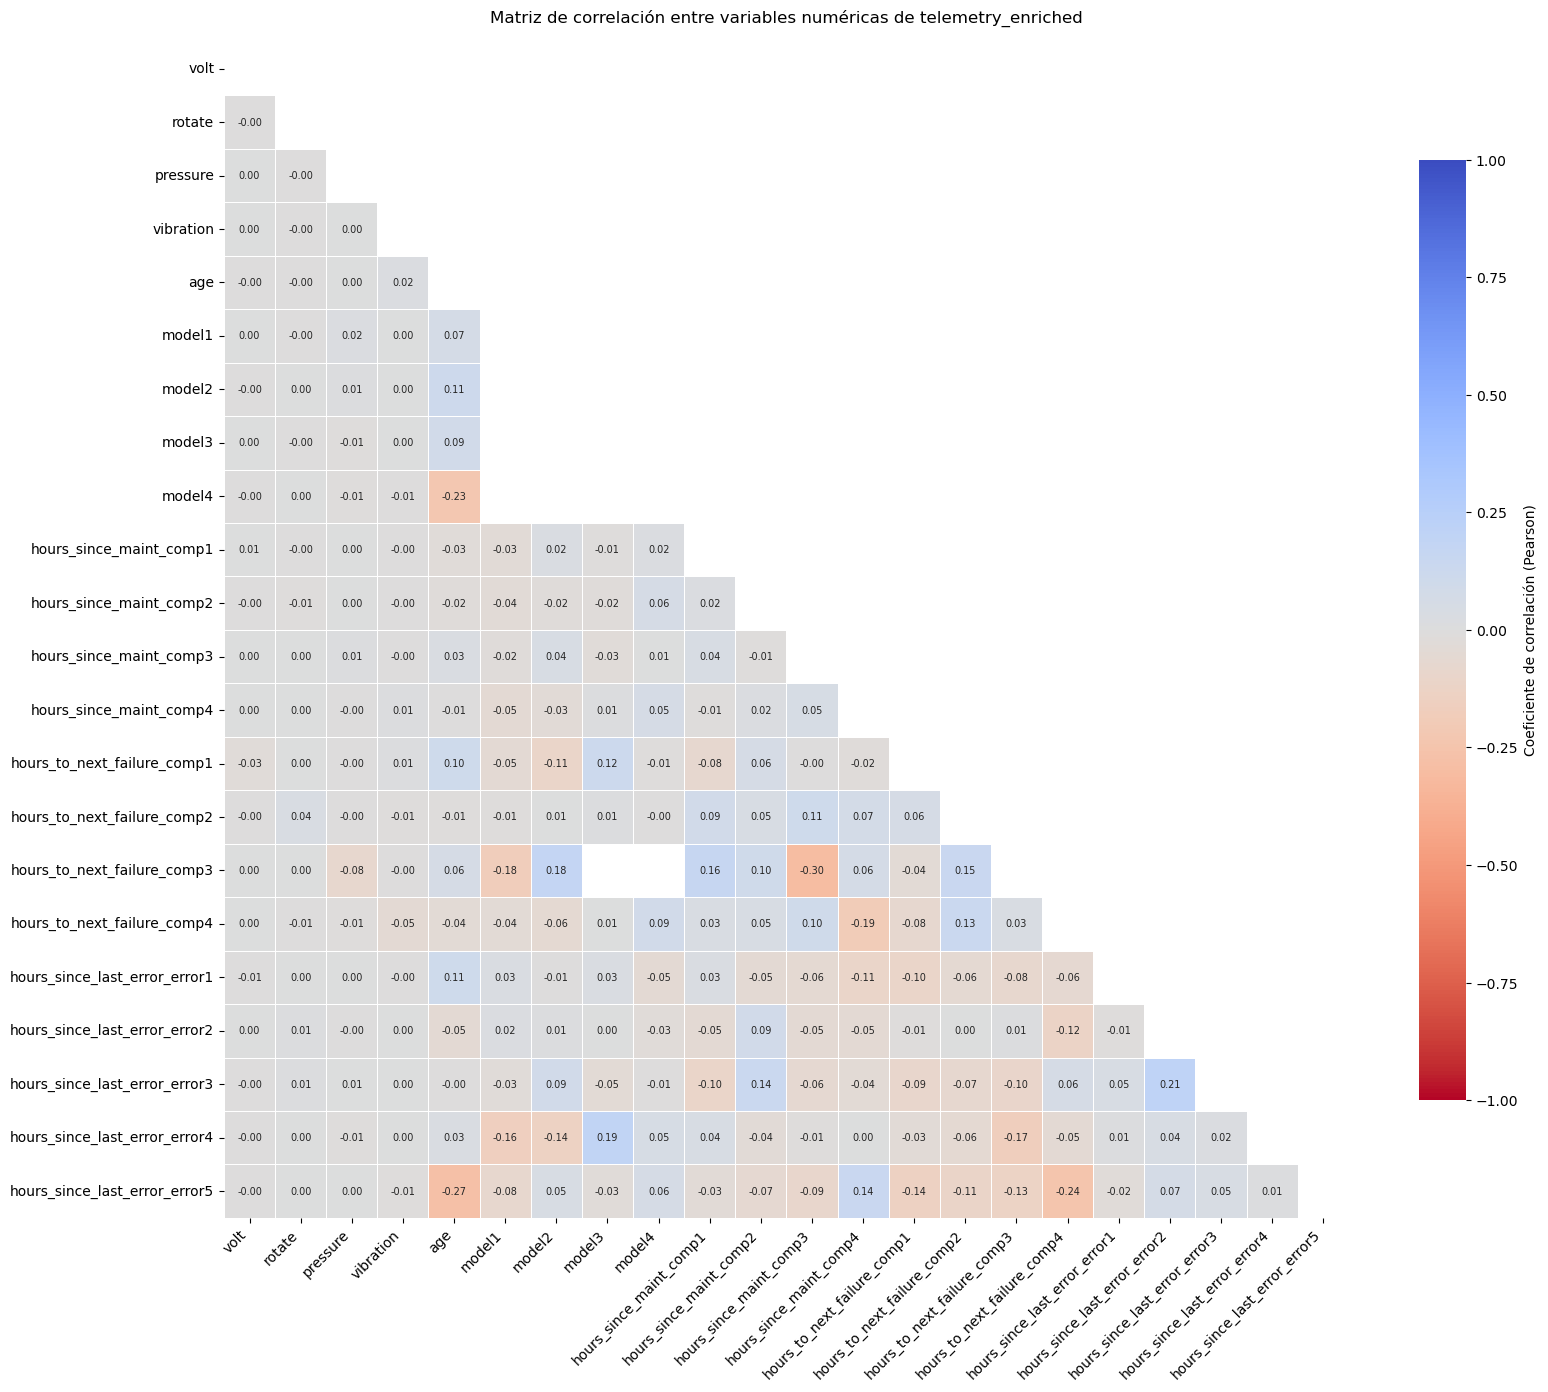

In [55]:
model_cols = [f"model{i}" for i in range(1, 5)]
columns_to_drop = ["datetime", "machineID"]

# Seleccionamos solo columnas numéricas para evitar errores con texto/categorías
corr_matrix = telemetry_enriched.drop(columns=columns_to_drop).corr(
    method="pearson", numeric_only=True
)

# Eliminamos las correlaciones entre las variables dummy de modelo para evitar
# información redundante
corr_matrix.loc[model_cols, model_cols] = np.nan

# Ocultamos la triangular superior para evitar información duplicada
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

n_vars = corr_matrix.shape[0]
fig_size = max(10, n_vars * 0.75)
annot_size = 9 if n_vars <= 15 else 7

plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    annot_kws={"size": annot_size},
    fmt=".2f",
    cmap="coolwarm_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de correlación (Pearson)"},
)

plt.title(
    "Matriz de correlación entre variables numéricas de telemetry_enriched",
    pad=14,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(images_dir, "correlation_pearson_matrix_telemetry_enriched.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

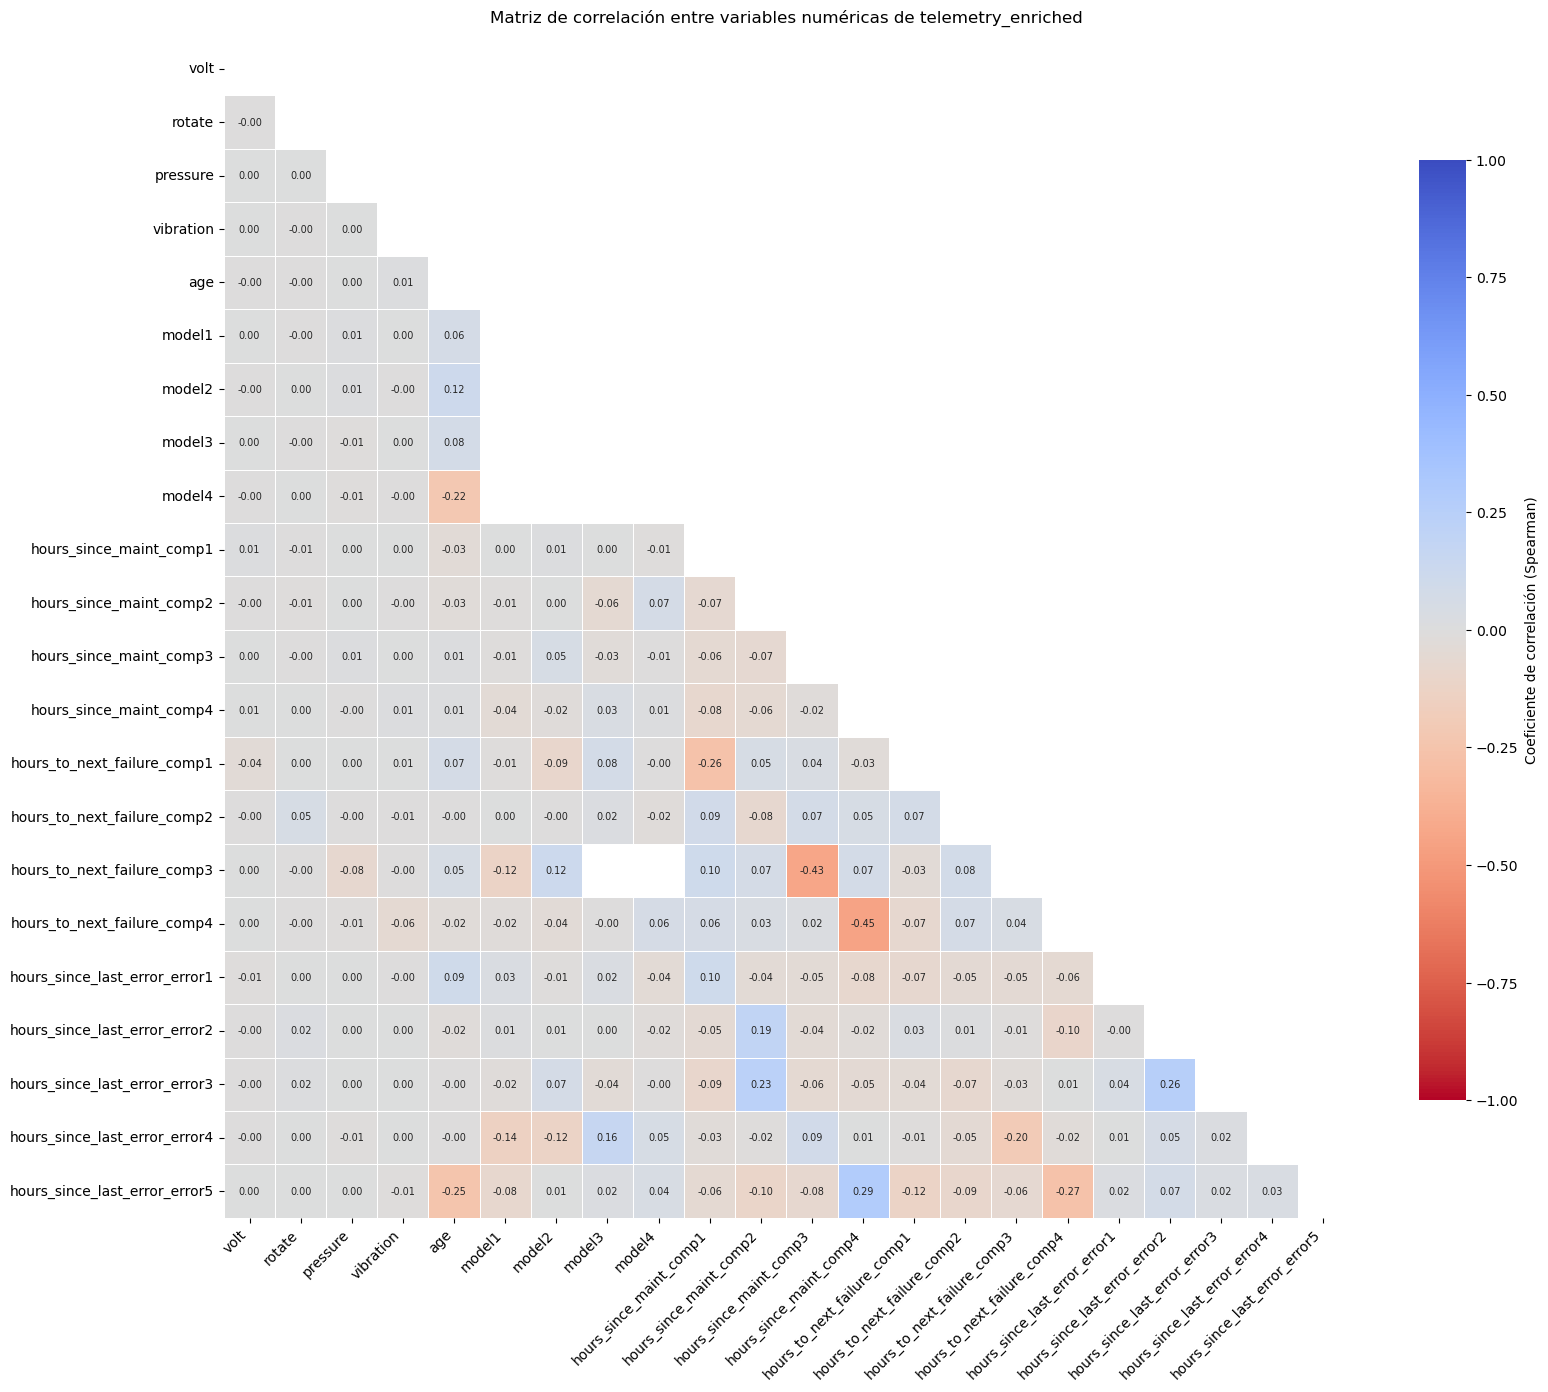

In [56]:
model_cols = [f"model{i}" for i in range(1, 5)]
columns_to_drop = ["datetime", "machineID"]

# Seleccionamos solo columnas numéricas para evitar errores con texto/categorías
corr_matrix = telemetry_enriched.drop(columns=columns_to_drop).corr(
    method="spearman", numeric_only=True
)

# Eliminamos las correlaciones entre las variables dummy de modelo para evitar
# información redundante
corr_matrix.loc[model_cols, model_cols] = np.nan

# Ocultamos la triangular superior para evitar información duplicada
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

n_vars = corr_matrix.shape[0]
fig_size = max(10, n_vars * 0.75)
annot_size = 9 if n_vars <= 15 else 7

plt.figure(figsize=(fig_size, fig_size * 0.85))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    annot_kws={"size": annot_size},
    fmt=".2f",
    cmap="coolwarm_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"shrink": 0.8, "label": "Coeficiente de correlación (Spearman)"},
)

plt.title(
    "Matriz de correlación entre variables numéricas de telemetry_enriched",
    pad=14,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(images_dir, "correlation_spearman_matrix_telemetry_enriched.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Escalado de los datos

## Feature Engineering